# Proyecto Final · Caso B: ¿Qué pedidos llegarán tarde?
**Distribuidora TransAndes**

**Integrantes:** _(Manuela Calero)_ · _(Laura Fernandez)_ · _(Alejandro Valencia)_ · _(Emanuel Puentes)_

---

> **Pregunta de negocio:** con la información disponible al momento del despacho, ¿podemos predecir si un pedido llegará tarde? ¿Qué condiciones de la operación aumentan el riesgo de retraso?

Seguimos la metodología **CRISP-DM** vista en clase. 

| Fase | Contenido |
|---|---|
| 1 · Comprensión del negocio | Problema, aciertos y errores, costo de cada error y métrica a priorizar |
| 2 · Comprensión de los datos (EDA) | Secciones 0 a 8 |
| 3 · Preparación de los datos | Duplicados, categorías, valores imposibles, nulos, codificación, división 70/30 |
| 4 · Modelado | Árbol de decisión y regresión logística, cada uno con varias configuraciones |
| 5 · Evaluación | Métricas, matrices de confusión, train vs. test, tabla comparativa y elección |
| 6 · Recomendaciones | Variables clave, recomendaciones para la gerencia y limitaciones |



## Fase 1 · Comprensión del negocio

**1. Descripción del problema y su importancia para la empresa**

TransAndes es una empresa distribuidora que realiza entregas desde cuatro centros de distribución ubicados en Cali, Bogotá, Medellín y Barranquilla. La compañía utiliza diferentes tipos de vehículos (motos, furgones y camiones) para transportar pedidos hacia zonas urbanas, periurbanas y rurales.

Actualmente, uno de los principales problemas de la empresa son los retrasos en las entregas. Esto afecta la satisfacción de los clientes, genera quejas, ocasiona penalidades con clientes empresariales y, al final, puede generar pérdida de clientes de hogar.

De acuerdo con el caso, aproximadamente 3 de cada 10 pedidos llegan tarde. Por esta razón, la empresa busca usar la información de cada despacho para identificar anticipadamente cuáles pedidos tienen mayor probabilidad de retrasarse.

El objetivo de este proyecto es desarrollar un modelo de clasificación que permita predecir si un pedido llegará tarde o a tiempo, utilizando las variables que la empresa conoce en el momento del despacho que son distancia, peso, paradas, hora de salida, clima, conductor, vehículo, cliente y prioridad.

La importancia de este análisis está en que TransAndes podría anticiparse a los posibles retrasos y tomar decisiones antes de que se presenten. De esta manera, el análisis de datos ayudaría a mejorar la eficiencia de la operación, reducir tanto quejas como posibles pérdidas de clientes y así mejorar la experiencia de los clientes.

**2. Definición de aciertos y errores del modelo**

Para este proyecto, la variable objetivo es `entrega_tardia`, que indica si un pedido llegó después de la ventana de entrega prometida. Tomamos como clase positiva "Sí, llegó tarde", porque es el evento que queremos detectar.

El modelo tendrá dos posibles resultados: predecir que un pedido llegará tarde o predecir que llegará a tiempo. Con esto se presentan cuatro situaciones:

| | El modelo dice **"a tiempo"** | El modelo dice **"tarde"** |
|---|---|---|
| **Realmente llegó a tiempo** | ✅ Verdadero negativo (VN) | ❌ Falso positivo (FP) |
| **Realmente llegó tarde** | ❌ Falso negativo (FN) | ✅ Verdadero positivo (VP) |

- **Verdadero positivo (VP):** el modelo predice que el pedido llegará tarde y efectivamente llega tarde. Es un acierto porque permite identificar anticipadamente un pedido que necesita atención.
- **Verdadero negativo (VN):** el modelo predice que el pedido llegará a tiempo y efectivamente cumple. También es un acierto.
- **Falso positivo (FP):** el modelo predice que el pedido llegará tarde, pero llega a tiempo. Es un error porque la empresa podría usar recursos adicionales sin necesidad.
- **Falso negativo (FN):** el modelo predice que el pedido llegará a tiempo, pero llega tarde. Es un error porque la empresa no identifica el riesgo y pierde la oportunidad de tomar medidas preventivas.

**3. Costos de los errores y métrica que se debe priorizar**

Para TransAndes, consideramos que el error más costoso es el **falso negativo (FN)** el modelo dice que el pedido llegará a tiempo, pero termina llegando tarde. Esto se debe a que la empresa no sabría del riesgo de retraso y no podría tomar medidas para evitarlo o reducir sus consecuencias. Esto genera inconformidad en los clientes, reclamaciones, penalidades económicas en los contratos empresariales y posibles pérdidas de clientes, es decir, un costo que se repite varias veces en el tiempo.

Por otro lado, un **falso positivo (FP)** también representa un costo, ya que la empresa podría tomar medidas adicionales sobre pedidos que iban a llegar a tiempo como por ejemplo  asignar otro vehículo o un conductor con más experiencia, modificar una ruta, sacar el pedido en otra hora o avisarle al cliente. Sin embargo, la mayoría de estas medidas son baratas y algunas como avisar al cliente casi no cuestan, por eso consideramos que este segundo error es menos costoso que dejar que un pedido llegue tarde sin haberlo anticipado, en especial con clientes empresariales o pedidos Express.

Por esta razón, la métrica que se debe priorizar es el Recall (sensibilidad) de la clase "tardía", porque mide qué proporción de los pedidos que realmente llegan tarde logra identificar el modelo. Un recall alto permite que TransAndes detecte la mayor cantidad posible de entregas en riesgo, reduciendo los falsos negativos. Eso no significa ignorar los falsos positivos, un modelo que marque todos los pedidos como tardíos tendría recall de 100 % pero no serviría para nada. Por eso, al comparar modelos, también vigilamos la precision que basicamente nos dice de los pedidos que el modelo alerta, cuántos sí llegan tarde y el F1, que combina ambas. Además, el accuracy por sí solo no sirve, como solo el 31 % de los pedidos llega tarde, un modelo que siempre diga "a tiempo" tendría 69 % de accuracy sin detectar un solo retraso.

## Fase 2 · Comprensión de los datos (EDA)

En esta fase conocemos bien la base de despachos antes de limpiarla o modelarla, nos fijamos en qué trae, qué le falta, qué problemas de calidad tiene y cómo se relaciona cada variable con la variable objetivo `entrega_tardia`. Aquí solo detectamos los problemas; la limpieza definitiva la vamos a hacer  en la Fase 3.



## 0. Configuración y carga de datos

Importamos las librerías y fijamos un estilo común para las gráficas. En todo el notebook vamos a usar azul para "llegó a tiempo" y naranja para "llegó tarde", así no hay que releer la leyenda en cada gráfico.

In [4]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid.axis": "y",
})

# Colores fijos para toda la fase: azul = llegó a tiempo, naranja = llegó tarde
COL_NO, COL_SI = "#4C72B0", "#DD8452"
PALETA = {"No": COL_NO, "Sí": COL_SI}

In [ ]:
from pathlib import Path

# El CSV debe estar en la misma carpeta
candidatos = ["logistica_entregas.csv", "logistica_entregas 2.csv"]
ruta = next((Path(c) for c in candidatos if Path(c).exists()), None)
if ruta is None:
    raise FileNotFoundError("No encontré el CSV. Ponlo en la misma carpeta del notebook.")

# utf-8-sig porque el archivo trae BOM al inicio (si no, la primera columna sale como 'ï»¿id_pedido')
df = pd.read_csv(ruta, encoding="utf-8-sig")
print(f"Archivo cargado: {ruta.name}")
df.head()

Archivo cargado: logistica_entregas.csv


,id_pedido,fecha_despacho,dia_semana,centro_distribucion,zona_destino,tipo_vehiculo,distancia_km,peso_kg,num_paradas,hora_salida,clima,experiencia_conductor_anios,edad_vehiculo_anios,tipo_cliente,prioridad,valor_pedido_COP,entrega_tardia
0,P-04180,2025-10-24,Viernes,Cali,Rural,Furgón,58.90,115.50,10.00,19.00,Lluvia,5.70,9.00,Empresa,Normal,"193,700.00",Sí
1,P-00296,2025-11-19,Miércoles,Bogotá,Urbana,Furgón,25.70,264.30,NaN,17.00,Lluvia,3.20,4.00,NaN,Normal,"361,300.00",Sí
2,P-02789,2025-02-23,Domingo,Medellín,Urbana,Moto,18.60,NaN,7.00,20.00,Soleado,NaN,5.00,Hogar,Express,"170,600.00",No
3,P-01284,2025-01-21,Martes,Bogotá,Urbana,Moto,5.10,9.20,1.00,6.00,Soleado,10.20,5.00,Empresa,Normal,"622,400.00",No
4,P-05152,2025-07-12,Sábado,Bogotá,Urbana,Furgón,14.20,260.50,1.00,5.00,Lluvia,6.50,15.00,Hogar,Normal,"406,500.00",No


## 1. Vista general de los datos

Empezamos con lo básico que es tamaño de la tabla, tipos de datos y estadísticas descriptivas.

In [3]:
filas, columnas = df.shape
print(f"El dataset tiene {filas:,} filas y {columnas} columnas.")
print(f"Periodo cubierto: {df['fecha_despacho'].min()} a {df['fecha_despacho'].max()}")

El dataset tiene 8,035 filas y 17 columnas.
Periodo cubierto: 2025-01-01 a 2025-12-31


La base coincide con la descrita en el enunciado: una fila por pedido despachado, 8.035 pedidos y 17 columnas, todos del año 2025. Veamos los tipos de dato y cuántos valores no nulos tiene cada columna.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8035 entries, 0 to 8034
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id_pedido                    8035 non-null   str    
 1   fecha_despacho               8035 non-null   str    
 2   dia_semana                   8035 non-null   str    
 3   centro_distribucion          8035 non-null   str    
 4   zona_destino                 8035 non-null   str    
 5   tipo_vehiculo                8035 non-null   str    
 6   distancia_km                 7633 non-null   float64
 7   peso_kg                      7391 non-null   float64
 8   num_paradas                  7550 non-null   float64
 9   hora_salida                  7713 non-null   float64
 10  clima                        7311 non-null   str    
 11  experiencia_conductor_anios  7149 non-null   float64
 12  edad_vehiculo_anios          7475 non-null   float64
 13  tipo_cliente                 

Lo que podemos saber del `info()`:

- Hay 7 variables numéricas todas `float64`, incluso las que son conteos como `num_paradas`, porque tienen nulos, 7 categóricas, el identificador, la fecha y la variable objetivo.
- `fecha_despacho` viene como texto. Para trabajar con fechas habría que convertirla a `datetime`.
- Ocho columnas están completas `id_pedido`, `fecha_despacho`, `dia_semana`, `centro_distribucion`, `zona_destino`, `tipo_vehiculo`, `prioridad` y `entrega_tardia`. Las otras nueve tienen datos faltantes.
- La variable objetivo es texto `Sí` / `No`, no está en 0/1.

In [ ]:
# Listas de columnas por tipo
num_cols = ["distancia_km", "peso_kg", "num_paradas", "hora_salida",
            "experiencia_conductor_anios", "edad_vehiculo_anios", "valor_pedido_COP"]
cat_cols = ["dia_semana", "centro_distribucion", "zona_destino", "tipo_vehiculo",
            "clima", "tipo_cliente", "prioridad"]
objetivo = "entrega_tardia"

df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
distancia_km,"7,633.00",34.21,36.32,-144.10,4.40,11.30,19.40,43.50,167.67,299.00
peso_kg,"7,391.00",370.06,616.10,0.00,2.99,10.45,143.30,328.05,"2,838.27","6,341.20"
num_paradas,"7,550.00",6.56,3.44,0.00,1.00,4.00,6.00,9.00,15.00,23.00
hora_salida,"7,713.00",12.53,4.59,5.00,5.00,9.00,12.00,16.00,20.00,30.00
experiencia_conductor_anios,"7,149.00",4.98,3.49,0.10,0.40,2.40,4.20,6.60,15.90,30.00
edad_vehiculo_anios,"7,475.00",7.35,4.58,0.00,0.00,3.00,7.00,11.00,15.00,15.00
valor_pedido_COP,"7,634.00","301,474.63","296,305.39","11,300.00","33,433.00","125,800.00","216,000.00","374,875.00","1,425,716.00","5,752,400.00"


Cosas que llaman la atención en el `describe()` numérico:

- `distancia_km` tiene un mínimo de -144.1 km y una distancia negativa es imposible, eso  seguramente un error de signo.
- `hora_salida` debería ir de 0 a 23, pero el máximo es 30. Además el mínimo es 5, o sea que los despachos reales salen entre las 5 y las 20 h.
- `peso_kg` tiene mínimo 0 y máximo 6.341 kg, y su media 370 es casi tres veces la mediana 143, es una variable muy asimétrica.
- `num_paradas` tiene un mínimo de 0, lo cual no tiene sentido en una ruta que entrega un pedido.
- `valor_pedido_COP` también es muy asimétrica, media de 301 mil y mediana de 216 mil, con un máximo de 5,7 millones.
- `experiencia_conductor_anios` llega hasta 30 años y `edad_vehiculo_anios` va de 0 a 15, ambos rangos son razonables.

In [7]:
df[cat_cols + [objetivo]].describe().T

,count,unique,top,freq
dia_semana,8035,7,Lunes,1206
centro_distribucion,8035,10,Cali,2688
zona_destino,8035,3,Urbana,4379
tipo_vehiculo,8035,7,Furgón,3487
clima,7311,4,Soleado,2891
tipo_cliente,7792,3,Hogar,3541
prioridad,8035,2,Normal,6056
entrega_tardia,8035,2,No,5513


En las categóricas el `unique` ya delata problemas: `centro_distribucion` tiene **10** categorías cuando la empresa solo tiene 4 centros, y `tipo_vehiculo` tiene **7** cuando solo hay 3 tipos de vehículo. Es decir, hay categorías escritas de distintas formas.

## 2. Valores nulos

Contamos cuántos datos faltan en cada columna, en cantidad y en porcentaje.

In [8]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": df.isna().mean() * 100,
})
nulos = nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)
display(nulos)

con_algun_nulo = df.isna().any(axis=1)
print(f"Columnas sin nulos: {df.shape[1] - len(nulos)} de {df.shape[1]}")
print(f"Filas con al menos un nulo: {con_algun_nulo.sum():,} ({con_algun_nulo.mean()*100:.1f}%)")
print(f"Filas con 2 o más nulos: {(df.isna().sum(axis=1) >= 2).sum():,}")

,nulos,porcentaje
experiencia_conductor_anios,886,11.03
clima,724,9.01
peso_kg,644,8.01
edad_vehiculo_anios,560,6.97
num_paradas,485,6.04
distancia_km,402,5.00
valor_pedido_COP,401,4.99
hora_salida,322,4.01
tipo_cliente,243,3.02


Columnas sin nulos: 8 de 17
Filas con al menos un nulo: 3,593 (44.7%)
Filas con 2 o más nulos: 906


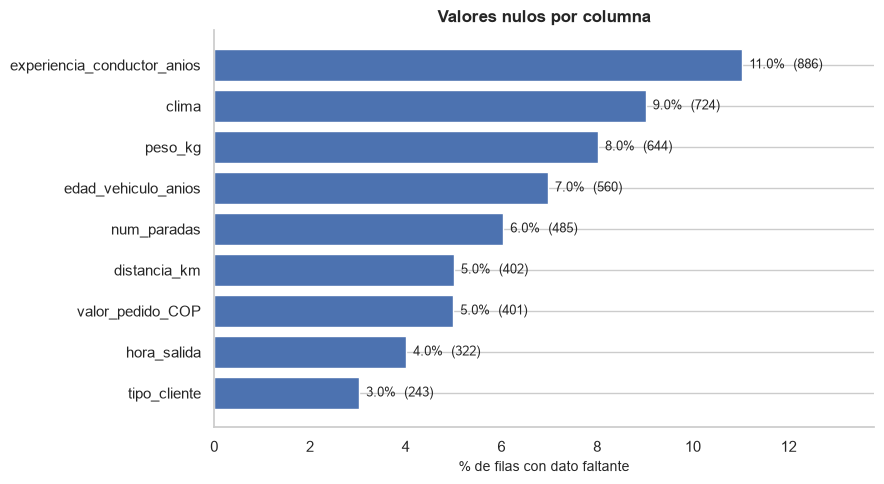

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
orden = nulos.sort_values("porcentaje")
barras = ax.barh(orden.index, orden["porcentaje"], color=COL_NO)
for b, (n, p) in zip(barras, zip(orden["nulos"], orden["porcentaje"])):
    ax.text(b.get_width() + 0.15, b.get_y() + b.get_height() / 2,
            f"{p:.1f}%  ({n:,})", va="center", fontsize=9)
ax.set_xlim(0, orden["porcentaje"].max() * 1.25)
ax.set_xlabel("% de filas con dato faltante")
ax.set_title("Valores nulos por columna")
plt.tight_layout()
plt.show()

Nueve de las 17 columnas tienen nulos, en proporciones la que más tiene es `experiencia_conductor_anios` 11 % y la que menos, `tipo_cliente` 3 %. Ninguna columna pasa del 11 %, así que por separado ninguna es tan grave como para pensar en descartarla. El problema es el efecto acumulado de ellas como los nulos están repartidos en muchas columnas, 44,7 % de las filas 3.593 de 8.035 tiene al menos un dato faltante. Si en la Fase 3 se optara por borrar todas las filas con nulos, perderíamos casi la mitad de la base, así que eso no parece una buena estrategia, toca  ir revisando  columna por columna. Algo que también nos interesa saber es si los nulos tienen relación con la variable objetivo. Si, por ejemplo, el clima faltara más en los pedidos que llegaron tarde, el hecho mismo de que falte sería informativo. Lo revisamos comparando el porcentaje de entregas tardías entre las filas donde el dato falta y donde existe.

In [10]:
# ¿Los datos faltan al azar o los nulos se relacionan con llegar tarde?
y_tmp = (df[objetivo] == "Sí").astype(int)
filas = []
for c in nulos.index:
    es_nulo = df[c].isna()
    filas.append({
        "columna": c,
        "% tarde si el dato es nulo": y_tmp[es_nulo].mean() * 100,
        "% tarde si el dato existe": y_tmp[~es_nulo].mean() * 100,
    })
comp = pd.DataFrame(filas).set_index("columna")
comp["diferencia (pp)"] = comp.iloc[:, 0] - comp.iloc[:, 1]
display(comp)

,% tarde si el dato es nulo,% tarde si el dato existe,diferencia (pp)
columna,,,
experiencia_conductor_anios,32.28,31.28,1.00
clima,29.70,31.56,-1.86
peso_kg,30.75,31.44,-0.70
edad_vehiculo_anios,32.32,31.32,1.00
num_paradas,34.02,31.22,2.80
distancia_km,30.60,31.43,-0.83
valor_pedido_COP,31.42,31.39,0.04
hora_salida,29.81,31.45,-1.64
tipo_cliente,30.04,31.43,-1.39


Las diferencias son pequeñas la más grande es de 2,8 puntos porcentuales, en `num_paradas` y no van en una dirección consistente. En general, las filas con dato faltante se retrasan casi igual que el resto alrededor de 31 %, por esto decimos que  los nulos se parecen más a datos que se perdieron al azar que a un patrón ligado al retraso, algo útil para decidir cómo imputarlos después. 

## 3. Problemas de calidad detectados

El enunciado ya avisa que la base viene sucia a propósito. Antes de analizar relaciones tenemos que saber qué errores trae, porque un valor de -144 km o una ciudad escrita como `CALI ` pueden distorsionar cualquier gráfica o promedio. En esta sección solo detectamos y medimos.
### 3.1 Registros duplicados

In [11]:
dup_filas = df.duplicated().sum()
dup_id = df["id_pedido"].duplicated().sum()
print(f"Filas completamente duplicadas: {dup_filas}")
print(f"IDs de pedido repetidos:        {dup_id}")

# Revisamos que los IDs repetidos sean copias exactas y no pedidos distintos con el mismo ID
ids_rep = df.loc[df["id_pedido"].duplicated(keep=False), "id_pedido"]
print(f"Pedidos afectados: {ids_rep.nunique()} (cada uno aparece {ids_rep.value_counts().unique().tolist()} veces)")
df[df["id_pedido"].duplicated(keep=False)].sort_values("id_pedido").head(6)

Filas completamente duplicadas: 35
IDs de pedido repetidos:        35
Pedidos afectados: 35 (cada uno aparece [2] veces)


,id_pedido,fecha_despacho,dia_semana,centro_distribucion,zona_destino,tipo_vehiculo,distancia_km,peso_kg,num_paradas,hora_salida,clima,experiencia_conductor_anios,edad_vehiculo_anios,tipo_cliente,prioridad,valor_pedido_COP,entrega_tardia
46,P-00156,2025-11-10,Lunes,Medellín,Periurbana,Moto,29.00,9.20,6.00,9.00,Soleado,6.70,14.00,Empresa,Normal,"372,300.00",No
1896,P-00156,2025-11-10,Lunes,Medellín,Periurbana,Moto,29.00,9.20,6.00,9.00,Soleado,6.70,14.00,Empresa,Normal,"372,300.00",No
235,P-00317,2025-08-16,Sábado,Bogotá,Urbana,Moto,8.30,7.80,3.00,10.00,Lluvia,NaN,11.00,Hogar,Normal,"116,800.00",No
7546,P-00317,2025-08-16,Sábado,Bogotá,Urbana,Moto,8.30,7.80,3.00,10.00,Lluvia,NaN,11.00,Hogar,Normal,"116,800.00",No
85,P-00328,2025-03-25,Martes,Barranquilla,Periurbana,Furgón,25.00,133.90,9.00,10.00,Lluvia,5.70,6.00,Tienda,Normal,"300,000.00",No
2827,P-00328,2025-03-25,Martes,Barranquilla,Periurbana,Furgón,25.00,133.90,9.00,10.00,Lluvia,5.70,6.00,Tienda,Normal,"300,000.00",No


Hay 35 pedidos que aparecen dos veces, con exactamente los mismos valores en todas las columnas incluido el ID. No son pedidos distintos con el mismo ID, son copias. Si los dejamos, esos 35 pedidos pesarían doble en cualquier análisis.

### 3.2 Categorías escritas de formas distintas

In [12]:
for c in ["centro_distribucion", "tipo_vehiculo"]:
    print(f"--- {c} ---")
    print(df[c].value_counts().to_string())
    print()

--- centro_distribucion ---
centro_distribucion
Cali            2688
Bogotá          2412
Medellín        1486
Barranquilla    1208
CALI              47
barranquilla      45
Medellin          40
BOGOTÁ            38
Bogota            37
cali              34

--- tipo_vehiculo ---
tipo_vehiculo
Furgón    3487
Moto      2813
Camión    1585
furgon      48
MOTO        39
Camion      32
Furgon      31



Aquí se ve el problema: "Cali" aparece como `Cali`, `CALI ` con espacio al final y `cali`, Bogotá como `Bogotá`, `BOGOTÁ` y `Bogota` sin tilde, y lo mismo con Medellín, Barranquilla y los tipos de vehículo `Moto` / `MOTO`, `Furgón` / `furgon` / `Furgon`, `Camión` / `Camion`. Son pocas filas cada una, pero si no se unifican, un modelo  las tratará como categorías distintas. Para asegurarnos de que el problema se limita a estas dos columnas, comparamos el número de categorías antes y después de normalizar el texto quitar espacios, pasar a minúscula y quitar tildes:

In [13]:
import unicodedata

def normalizar(s):
    """Minúsculas, sin espacios sobrantes y sin tildes: sirve para comparar si dos textos son 'el mismo'."""
    return (s.str.strip().str.lower()
             .map(lambda t: unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode() if isinstance(t, str) else t))

resumen = pd.DataFrame({
    "categorías como vienen": [df[c].nunique() for c in cat_cols],
    "categorías tras normalizar": [normalizar(df[c]).nunique() for c in cat_cols],
}, index=cat_cols)
resumen["hay problema"] = resumen.iloc[:, 0] != resumen.iloc[:, 1]
resumen

,categorías como vienen,categorías tras normalizar,hay problema
dia_semana,7,7,False
centro_distribucion,10,4,True
zona_destino,3,3,False
tipo_vehiculo,7,3,True
clima,4,4,False
tipo_cliente,3,3,False
prioridad,2,2,False


Solo `centro_distribucion` 10 → 4 y `tipo_vehiculo` 7 → 3 tienen el problema. Las demás categóricas están bien escritas.

### 3.3 Valores imposibles o sospechosos

In [14]:
veh_norm = normalizar(df["tipo_vehiculo"])

# Peso "extremo" para su tipo de vehículo: mucho más allá del rango habitual de ese vehículo
def peso_extremo(grupo):
    q1, q3 = grupo.quantile([.25, .75])
    return grupo > q3 + 10 * (q3 - q1)
peso_ext = df.groupby(veh_norm)["peso_kg"].transform(lambda g: peso_extremo(g)).fillna(False).astype(bool)

reglas = pd.DataFrame([
    ("distancia_km <= 0",              "Una ruta no puede tener distancia negativa o cero",          (df["distancia_km"] <= 0).sum()),
    ("hora_salida fuera de 0-23",      "Las horas válidas van de 0 a 23 (se ven 25 y 30)",           (df["hora_salida"] > 23).sum()),
    ("peso_kg == 0",                   "Un pedido despachado tiene que pesar algo",                  (df["peso_kg"] == 0).sum()),
    ("num_paradas == 0",               "Una ruta con 0 entregas contradice que se despachó un pedido", (df["num_paradas"] == 0).sum()),
    ("peso extremo según vehículo",    "Ej.: motos con cientos de kg (lo normal en moto es < 50 kg)", peso_ext.sum()),
], columns=["regla", "por qué es sospechoso", "filas afectadas"]).set_index("regla")
display(reglas)

# Coherencia entre fecha y día de la semana
dias = {0: "Lunes", 1: "Martes", 2: "Miércoles", 3: "Jueves", 4: "Viernes", 5: "Sábado", 6: "Domingo"}
dia_real = pd.to_datetime(df["fecha_despacho"]).dt.dayofweek.map(dias)
print(f"Filas donde dia_semana no coincide con fecha_despacho: {(dia_real != df['dia_semana']).sum()}")

,por qué es sospechoso,filas afectadas
regla,,
distancia_km <= 0,Una ruta no puede tener distancia negativa o cero,20
hora_salida fuera de 0-23,Las horas válidas van de 0 a 23 (se ven 25 y 30),10
peso_kg == 0,Un pedido despachado tiene que pesar algo,15
num_paradas == 0,Una ruta con 0 entregas contradice que se desp...,59
peso extremo según vehículo,Ej.: motos con cientos de kg (lo normal en mot...,31


Filas donde dia_semana no coincide con fecha_despacho: 0


Definimos algunas reglas de sentido común y contamos cuántas filas las incumplen:

- **Distancia negativa o cero** 20 filas: no tiene sentido físico. Por la magnitud de varios -144, -118, -96 parece más un error de signo que un dato real.
- **Hora de salida 25 o 30** 10 filas: el reloj solo llega a 23.
- **Peso igual a 0** 15 filas y **paradas igual a 0** 59 filas: un pedido despachado pesa algo y la ruta tiene al menos una entrega.
- **Peso extremo para su vehículo** 31 filas: para ver esto hay que mirar el peso dentro de cada tipo de vehículo, porque entre vehículos es normal que cambie mucho. Hay motos con cientos o incluso 1.900 kg, algo imposible para una moto. Usamos una regla bastante exigente más de 10 veces el rango intercuartílico por encima del tercer cuartil de su vehículo para marcar solo los casos claramente absurdos. Además verificamos que `dia_semana` fuera coherente con `fecha_despacho` y  coincide en todas las filas, así que esa columna no tiene errores.

In [15]:
# Valores raros pero que podrían ser reales (no los tocamos como "imposibles")
print("Distancia > 200 km:", (df["distancia_km"] > 200).sum(), "filas (todas en zona rural:",
      df.loc[df["distancia_km"] > 200, "zona_destino"].eq("Rural").all(), ")")
print("Valor del pedido > 2 millones COP:", (df["valor_pedido_COP"] > 2_000_000).sum(), "filas")
print("Experiencia >= 25 años:", (df["experiencia_conductor_anios"] >= 25).sum(), "filas")
print("Edad del vehículo = 0 años (vehículo nuevo):", (df["edad_vehiculo_anios"] == 0).sum(), "filas")
df.groupby(veh_norm)["peso_kg"].describe()

Distancia > 200 km: 32 filas (todas en zona rural: True )
Valor del pedido > 2 millones COP: 28 filas
Experiencia >= 25 años: 4 filas
Edad del vehículo = 0 años (vehículo nuevo): 468 filas


,count,mean,std,min,25%,50%,75%,max
tipo_vehiculo,,,,,,,,
camion,"1,486.00","1,359.66",760.84,0.00,839.42,"1,205.70","1,679.50","6,341.20"
furgon,"3,285.00",206.19,131.82,0.00,128.70,180.50,252.40,"2,166.70"
moto,"2,620.00",14.25,70.98,0.00,5.70,8.00,11.50,"1,914.60"


Estos otros valores son raros pero no los consideramos imposibles, las 32 distancias de más de 200 km son todas de zona rural donde las rutas son largas, los pedidos de más de 2 millones de pesos son poco frecuentes pero posibles, y una experiencia de 25 años o más o un vehículo nuevo edad 0 son perfectamente plausibles. La tabla de abajo muestra por qué el peso hay que leerlo por vehículo, la mediana es 8 kg en motos, 180 en furgones y 1.200 en camiones. Los máximos de moto 1.915 y furgón 2.167 son los que se salen de lo normal.

### 3.4 Copia de trabajo para el EDA

Para que las gráficas de las siguientes secciones no se distorsionen, armamos una copia  donde solo para el analisis hagamos esto:

1. se eliminan los 35 duplicados
2. se unifican los nombres de centro y vehículo
3. los valores imposibles se convierten en nulo así simplemente no se grafican
4. se agrega una columna `tardia` en 0/1 para poder calcular promedios y correlaciones.

El DataFrame original `df` queda intacto, y todo lo anterior nulos, duplicados, categorías se midió sobre él. La limpieza definitiva, con la justificación de cada decisión y el tratamiento de los nulos, la hacemos en la Fase 3.

In [17]:
# Copia de trabajo solo para que las gráficas no se deformen.
# La limpieza formal y su justificación es la Fase 3.
df_eda = df.drop_duplicates().copy()

mapa_centro = {"cali": "Cali", "bogota": "Bogotá", "medellin": "Medellín", "barranquilla": "Barranquilla"}
mapa_veh = {"moto": "Moto", "furgon": "Furgón", "camion": "Camión"}
df_eda["centro_distribucion"] = normalizar(df_eda["centro_distribucion"]).map(mapa_centro)
df_eda["tipo_vehiculo"] = normalizar(df_eda["tipo_vehiculo"]).map(mapa_veh)

# Valores imposibles -> nulo (solo en esta copia)
df_eda.loc[df_eda["distancia_km"] <= 0, "distancia_km"] = np.nan
df_eda.loc[df_eda["hora_salida"] > 23, "hora_salida"] = np.nan
df_eda.loc[df_eda["peso_kg"] == 0, "peso_kg"] = np.nan
df_eda.loc[df_eda["num_paradas"] == 0, "num_paradas"] = np.nan
ext = df_eda.groupby("tipo_vehiculo")["peso_kg"].transform(lambda g: g > g.quantile(.75) + 10 * (g.quantile(.75) - g.quantile(.25)))
df_eda.loc[ext, "peso_kg"] = np.nan

# Variables auxiliares para el análisis
df_eda["tardia"] = (df_eda[objetivo] == "Sí").astype(int)
df_eda["fecha_despacho"] = pd.to_datetime(df_eda["fecha_despacho"])
df_eda["mes"] = df_eda["fecha_despacho"].dt.month

TASA_GLOBAL = df_eda["tardia"].mean()
print(f"Filas: {len(df):,} -> {len(df_eda):,} (se quitaron {len(df) - len(df_eda)} duplicados)")
print(f"Tasa global de entregas tardías: {TASA_GLOBAL*100:.1f}%")
print("Categorías de centro:", sorted(df_eda['centro_distribucion'].unique()))
print("Categorías de vehículo:", sorted(df_eda['tipo_vehiculo'].unique()))

Filas: 8,035 -> 8,000 (se quitaron 35 duplicados)
Tasa global de entregas tardías: 31.3%
Categorías de centro: ['Barranquilla', 'Bogotá', 'Cali', 'Medellín']
Categorías de vehículo: ['Camión', 'Furgón', 'Moto']


## 4. Análisis univariado

Ahora miramos cada variable por separado, empezando por las numéricas.

### 4.1 Variables numéricas

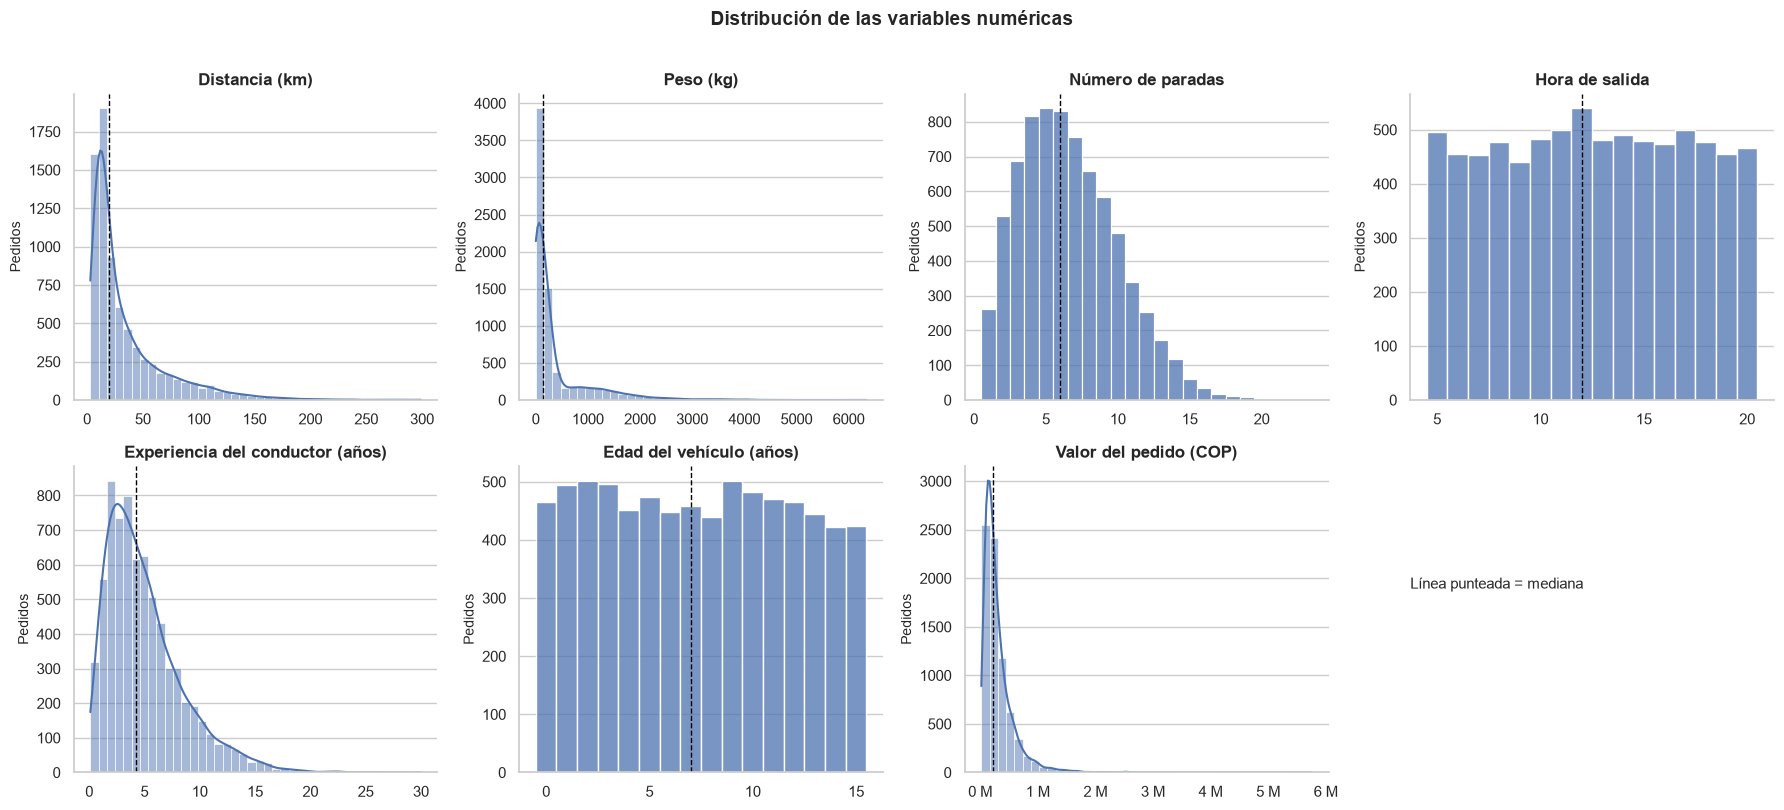

In [18]:
discretas = ["num_paradas", "hora_salida", "edad_vehiculo_anios"]
etiquetas = {
    "distancia_km": "Distancia (km)", "peso_kg": "Peso (kg)", "num_paradas": "Número de paradas",
    "hora_salida": "Hora de salida", "experiencia_conductor_anios": "Experiencia del conductor (años)",
    "edad_vehiculo_anios": "Edad del vehículo (años)", "valor_pedido_COP": "Valor del pedido (COP)",
}

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, c in zip(axes, num_cols):
    datos = df_eda[c].dropna()
    if c in discretas:
        sns.histplot(datos, discrete=True, ax=ax, color=COL_NO, edgecolor="white")
    else:
        sns.histplot(datos, bins=40, kde=True, ax=ax, color=COL_NO, edgecolor="white")
    ax.axvline(datos.median(), color="black", ls="--", lw=1)
    ax.set_title(etiquetas[c])
    ax.set_xlabel("")
    ax.set_ylabel("Pedidos")
    if c == "valor_pedido_COP":
        ax.xaxis.set_major_formatter(lambda x, pos: f"{x/1e6:.0f} M")
axes[-1].axis("off")
axes[-1].text(0, 0.6, "Línea punteada = mediana", fontsize=11)
plt.suptitle("Distribución de las variables numéricas", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

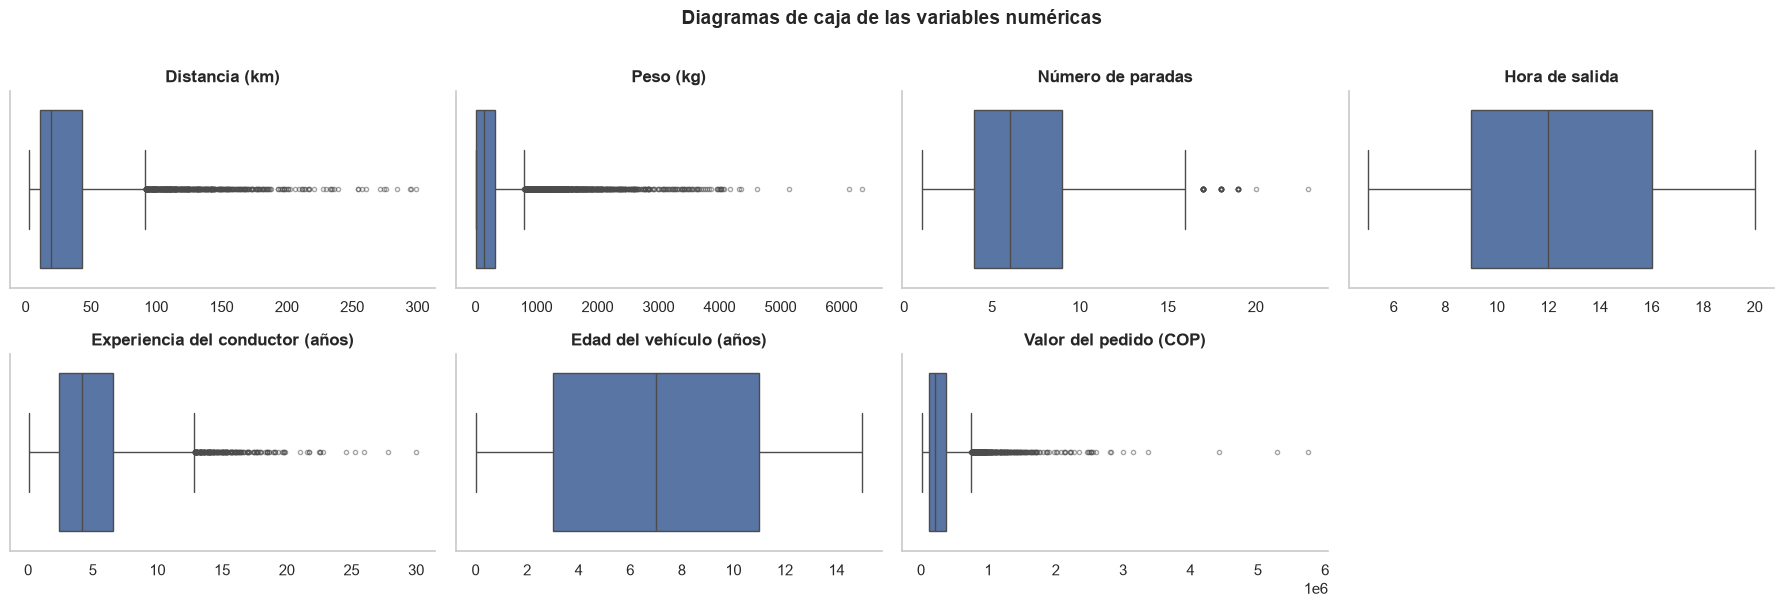

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
axes = axes.ravel()
for ax, c in zip(axes, num_cols):
    sns.boxplot(x=df_eda[c], ax=ax, color=COL_NO, flierprops={"markersize": 3, "alpha": .5})
    ax.set_title(etiquetas[c])
    ax.set_xlabel("")
axes[-1].axis("off")
plt.suptitle("Diagramas de caja de las variables numéricas", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

In [20]:
resumen_num = df_eda[num_cols].agg(["mean", "median", "std", "skew"]).T
q1, q3 = df_eda[num_cols].quantile(.25), df_eda[num_cols].quantile(.75)
lim_sup = q3 + 1.5 * (q3 - q1)
lim_inf = q1 - 1.5 * (q3 - q1)
resumen_num["% atípicos (regla 1.5·IQR)"] = [
    ((df_eda[c] > lim_sup[c]) | (df_eda[c] < lim_inf[c])).sum() / df_eda[c].notna().sum() * 100 for c in num_cols
]
resumen_num.columns = ["media", "mediana", "desv. estándar", "asimetría", "% atípicos (regla 1.5·IQR)"]
resumen_num

,media,mediana,desv. estándar,asimetría,% atípicos (regla 1.5·IQR)
distancia_km,34.37,19.50,35.99,2.27,8.34
peso_kg,369.31,142.80,616.28,2.84,15.85
num_paradas,6.61,6.00,3.41,0.56,0.52
hora_salida,12.51,12.00,4.57,-0.01,0.00
experiencia_conductor_anios,4.98,4.20,3.48,1.36,3.71
edad_vehiculo_anios,7.36,7.00,4.58,0.03,0.00
valor_pedido_COP,"301,391.92","215,900.00","296,078.41",4.41,6.13


Qué nos dicen estas distribuciones:

- **Distancia:** muy concentrada en rutas cortas mediana de 19,5 km con una cola larga a la derecha que llega a casi 300 km. Es una distribución sesgada asimetría de 2,3 y la media 34 km queda bastante por encima de la mediana. 
- **Peso:** tiene una forma extraña, con un pico enorme cerca de cero y una cola larga. No es un solo grupo, son tres poblaciones mezcladas motos de unos 8 kg, furgones de unos 180 kg y camiones de unos 1.200 kg. Por eso la regla de atípicos marca 16 % de valores "atípicos" son en gran parte camiones normales frente al conjunto, no errores.
- **Número de paradas:** forma de campana ligeramente sesgada a la derecha, centrada en 6 paradas, con algunas rutas de más de 15.
- **Hora de salida:** una vez excluidos los valores imposibles, es casi uniforme entre las 5 y las 20 h cada hora tiene entre 440 y 540 pedidos. Esto es importante, no hay una hora "popular" que explique por sí sola nada, así que si la hora influye en el retraso tendremos que ver en el análisis bivariado.
- **Experiencia del conductor:** asimétrica a la derecha. La mediana es 4,2 años y hay pocos conductores con más de 15 años.
- **Edad del vehículo:** también casi uniforme, de 0 a 15 años.
- **Valor del pedido:** la más sesgada de todas asimetría 4,4. Casi todos los pedidos valen menos de un millón y unos pocos son muy caros.

En los diagramas de caja se ven los atípicos. Los de distancia, experiencia y valor son colas legítimas de variables con sesgo y no necesariamente errores. 
### 4.2 Variables categóricas

In [21]:
partes = []
for c in cat_cols + [objetivo]:
    t = df_eda[c].value_counts(dropna=False).rename("pedidos").to_frame()
    t["%"] = t["pedidos"] / len(df_eda) * 100
    t.index = pd.MultiIndex.from_product([[c], t.index.fillna("(nulo)")])
    partes.append(t)
pd.concat(partes)

pedidos     %
dia_semana          Lunes             1200 15.00
                    Miércoles         1170 14.62
                    Domingo           1146 14.32
                    Viernes           1133 14.16
                    Jueves            1129 14.11
                    Martes            1116 13.95
                    Sábado            1106 13.83
centro_distribucion Cali              2761 34.51
                    Bogotá            2475 30.94
                    Medellín          1517 18.96
                    Barranquilla      1247 15.59
zona_destino        Urbana            4361 54.51
                    Periurbana        2220 27.75
                    Rural             1419 17.74
tipo_vehiculo       Furgón            3547 44.34
                    Moto              2841 35.51
                    Camión            1612 20.15
clima               Soleado           2874 35.93
                    Nublado           2064 25.80
                    Lluvia            1583 19.79
                    Lluvia fuerte      759  9.49
                    (nulo)             720  9.00
tipo_cliente        Hogar             3527 44.09
                    Empresa           2304 28.80
                    Tienda            1929 24.11
                    (nulo)             240  3.00
prioridad           Normal            6028 75.35
                    Express           1972 24.65
entrega_tardia      No                5493 68.66
                    Sí                2507 31.34

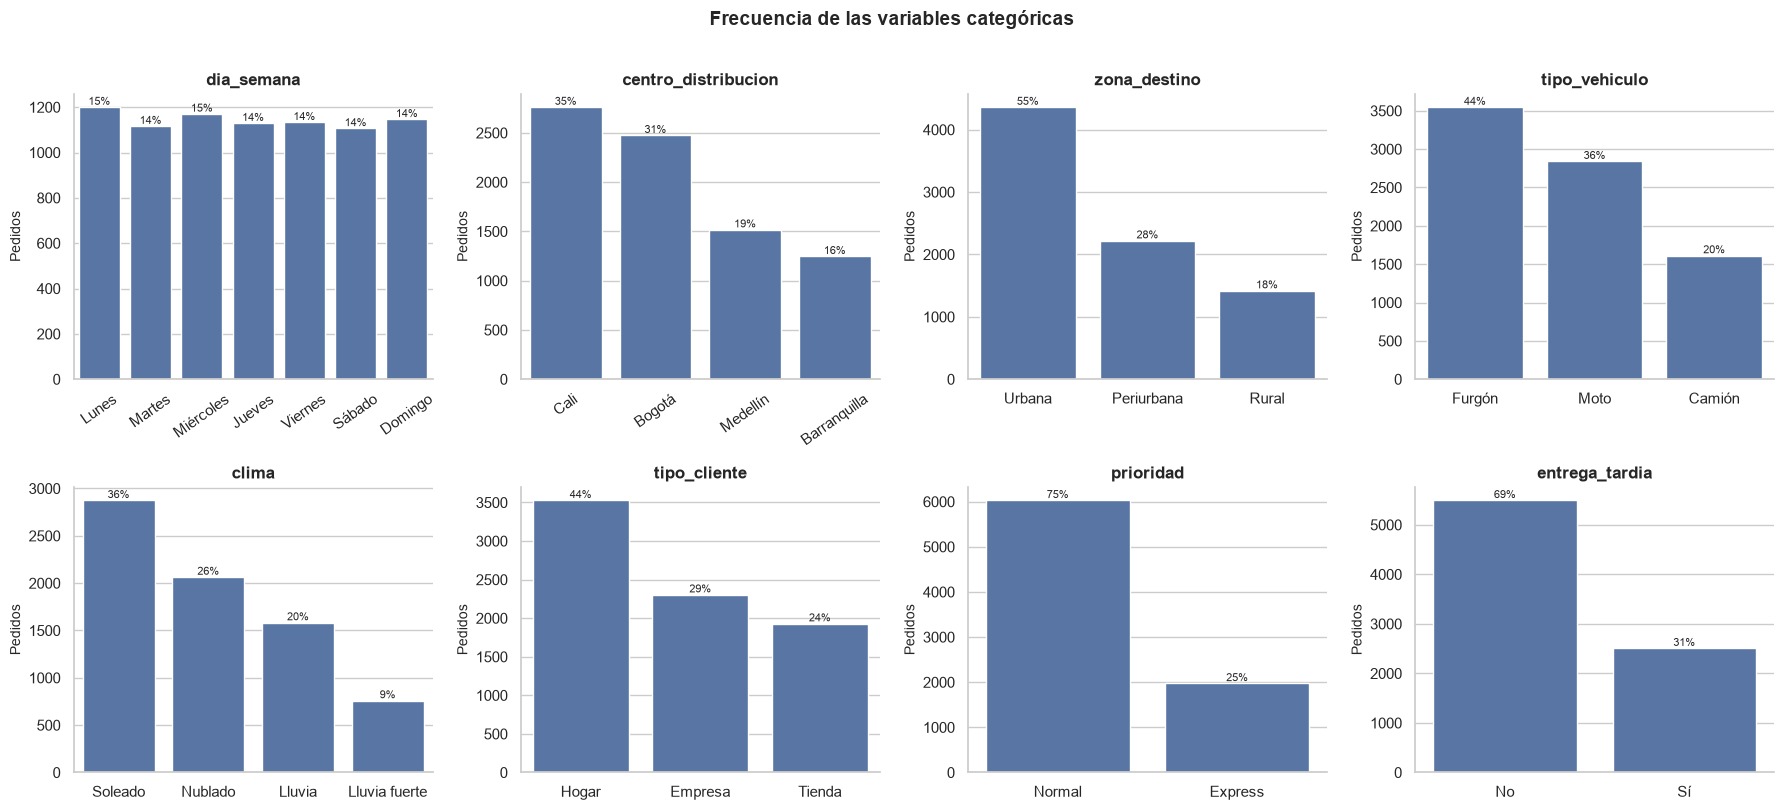

In [22]:
orden_dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, c in zip(axes, cat_cols + [objetivo]):
    orden = orden_dias if c == "dia_semana" else df_eda[c].value_counts().index
    sns.countplot(data=df_eda, x=c, order=orden, ax=ax, color=COL_NO)
    for p in ax.patches:
        ax.annotate(f"{p.get_height()/len(df_eda)*100:.0f}%", (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)
    ax.set_title(c)
    ax.set_xlabel("")
    ax.set_ylabel("Pedidos")
    ax.tick_params(axis="x", rotation=35 if c in ("dia_semana", "centro_distribucion") else 0)
plt.suptitle("Frecuencia de las variables categóricas", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

Lo que vemos en las frecuencias (ya con los nombres unificados):

- **Centros:** Cali 35 % y Bogotá 31 % concentran dos tercios de los despachos, Medellín tiene 19 % y Barranquilla 16 %.
- **Zona de destino:** más de la mitad de los pedidos es urbana 55 %, 28 % periurbana y 18 % rural.
- **Vehículo:** el furgón es el más usado 44 %, luego la moto 36 % y el camión 20 %.
- **Clima:** predomina el soleado 36 % y la lluvia fuerte es lo menos frecuente 9,5 %. Además, el 9 % de los clima son nulos.
- **Cliente:** 44 % hogar, 29 % empresa y 24 % tienda.
- **Prioridad:** tres de cada cuatro pedidos son de prioridad normal y uno de cada cuatro es Express.
- **Día de la semana:** muy parejo, entre 14 % y 15 % cada día.

Ninguna categoría es tan rara como para preocuparnos de que quede con muy pocos ejemplos, así que no hay grupos casi vacíos.

## 5. Análisis bivariado: cada variable frente a la entrega tardía

Aquí buscamos qué variables se relacionan con que un pedido llegue tarde. Para las categóricas calculamos el porcentaje de entregas tardías en cada categoría y lo comparamos con el promedio general línea punteada, 31,3 %. Para las numéricas combinamos un diagrama de caja con el porcentaje de tardías por rangos.

Primero definimos dos funciones auxiliares para no repetir código en cada gráfica.

In [24]:
def tasa_por(col, ax, orden=None, titulo=None, datos=None, rot=0):
    """Barras con el % de entregas tardías para cada categoría de `col`, con el n debajo."""
    d = df_eda if datos is None else datos
    g = d.groupby(col, observed=True)["tardia"].agg(["mean", "size"])
    if orden is not None:
        g = g.reindex(orden)
    barras = ax.bar(range(len(g)), g["mean"] * 100, color=COL_SI, edgecolor="white")
    ax.axhline(TASA_GLOBAL * 100, color="gray", ls="--", lw=1, label=f"Promedio general ({TASA_GLOBAL*100:.1f}%)")
    ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), frameon=False, fontsize=8)
    for b, m in zip(barras, g["mean"]):
        ax.text(b.get_x() + b.get_width()/2, m * 100 + 1, f"{m*100:.0f}%", ha="center", fontsize=9)
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([f"{i}\n(n={n:,})" for i, n in zip(g.index, g["size"])], rotation=rot, fontsize=9)
    ax.set_ylabel("% de entregas tardías")
    ax.set_ylim(0, max(g["mean"].max() * 100 * 1.18, TASA_GLOBAL * 100 * 1.3))
    ax.set_title(titulo or f"Tardías según {col}", pad=22)
    return g

def caja_por_objetivo(col, ax, titulo=None):
    sns.boxplot(data=df_eda, x=objetivo, y=col, order=["No", "Sí"], hue=objetivo, hue_order=["No", "Sí"], palette=PALETA, legend=False, ax=ax,
                flierprops={"markersize": 2, "alpha": .4})
    ax.set_xlabel("¿Entrega tardía?")
    ax.set_title(titulo or col)

### Gráfica 1 · Zona de destino

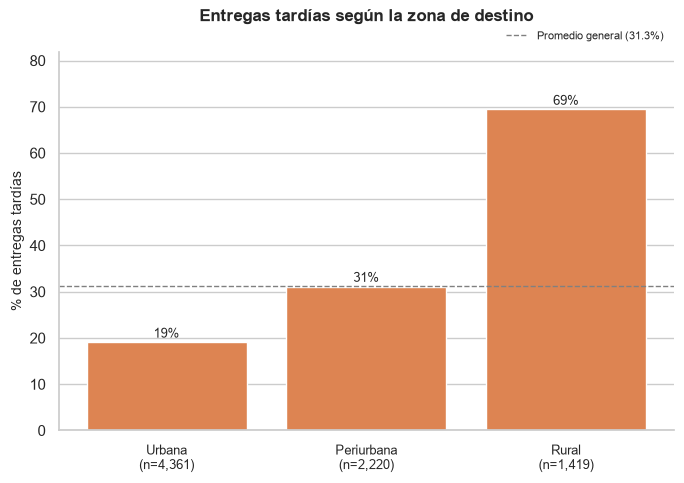

In [26]:
fig, ax = plt.subplots(figsize=(7, 5))
g = tasa_por("zona_destino", ax, orden=["Urbana", "Periurbana", "Rural"], titulo="Entregas tardías según la zona de destino")
plt.tight_layout()
plt.show()

Esta es  la diferencia más grande de todo el análisis. En zona urbana llega tarde el 19 % de los pedidos, en la periurbana el 31 % igual al promedio y en la rural el 69 %, casi 7 de cada 10 pedidos rurales llegan tarde. Aunque la zona rural es solo el 18 % de los pedidos, aporta una parte desproporcionada de los retrasos. Si TransAndes quiere reducir los retrasos, la zona rural es el primer lugar donde tiene que  mirar que hacer.

### Gráfica 2 · Distancia de la ruta

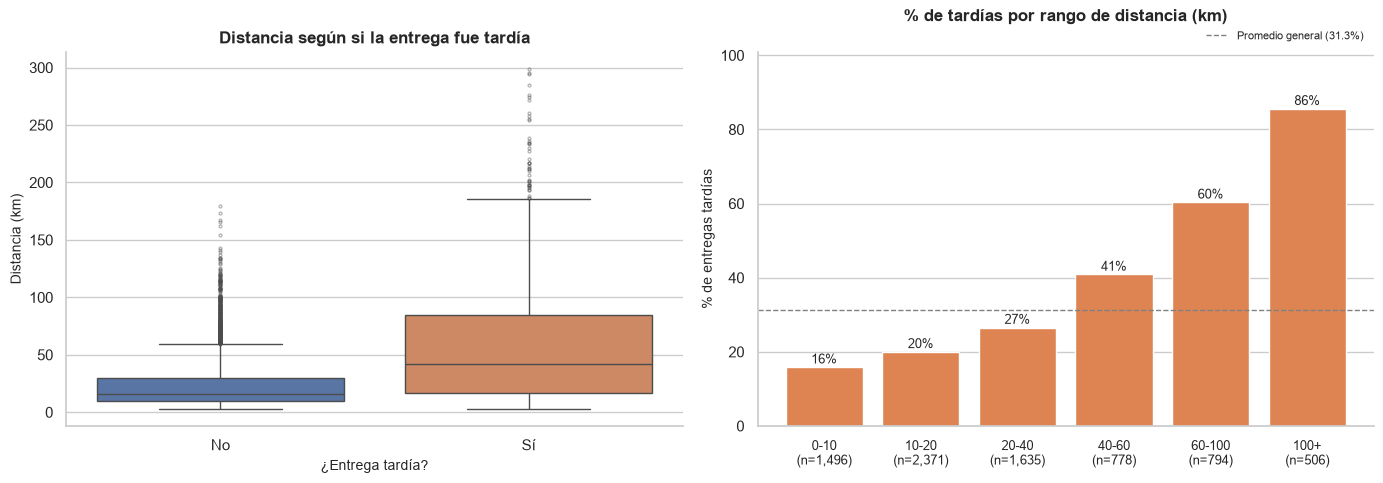

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
caja_por_objetivo("distancia_km", axes[0], "Distancia según si la entrega fue tardía")
axes[0].set_ylabel("Distancia (km)")

bins = [0, 10, 20, 40, 60, 100, 400]
etq = ["0-10", "10-20", "20-40", "40-60", "60-100", "100+"]
df_eda["rango_dist"] = pd.cut(df_eda["distancia_km"], bins=bins, labels=etq)
tasa_por("rango_dist", axes[1], orden=etq, titulo="% de tardías por rango de distancia (km)")
plt.tight_layout()
plt.show()

La relación es clara y creciente. Los pedidos que llegaron tarde tienen una mediana de 41,8 km frente a 15,9 km de los que llegaron a tiempo. Por rangos, el porcentaje de tardías sube de 16 % en rutas de menos de 10 km hasta 86 % en rutas de más de 100 km. La gran mayoría de los pedidos de más de 100 km llega tarde. Hay que tener en cuenta que la distancia y la zona están muy relacionadas la mediana es 12 km en urbana, 34 km en periurbana y 86 km en rural, así que parte de lo que vemos en la gráfica 1 y esta es lo mismo visto de dos formas.

### Gráfica 3 · Número de paradas

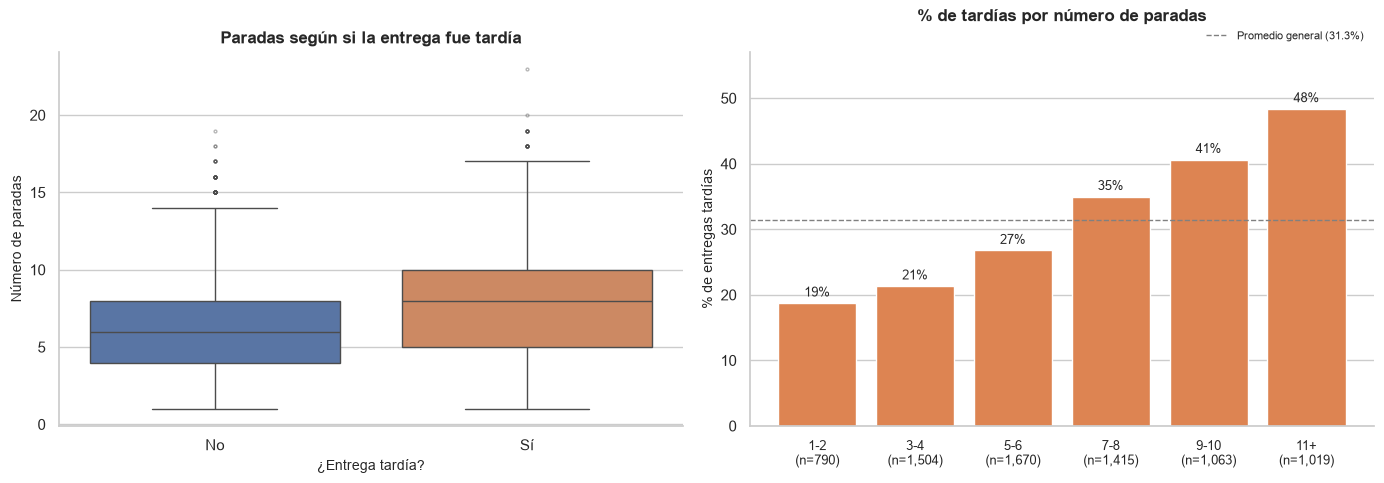

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
caja_por_objetivo("num_paradas", axes[0], "Paradas según si la entrega fue tardía")
axes[0].set_ylabel("Número de paradas")

bins = [0, 2, 4, 6, 8, 10, 30]
etq = ["1-2", "3-4", "5-6", "7-8", "9-10", "11+"]
df_eda["rango_paradas"] = pd.cut(df_eda["num_paradas"], bins=bins, labels=etq)
tasa_por("rango_paradas", axes[1], orden=etq, titulo="% de tardías por número de paradas")
plt.tight_layout()
plt.show()

A más paradas, más retraso, y de forma bastante lineal porque de 19 % en rutas con 1 o 2 paradas a 48 % en rutas con 11 o más. Tiene sentido operativo, porque cada parada suma tiempo y acumula la probabilidad de que algo se retrase. Las entregas tardías tienen una mediana de 8 paradas contra 6 de las que llegaron a tiempo. 

### Gráfica 4 · Clima

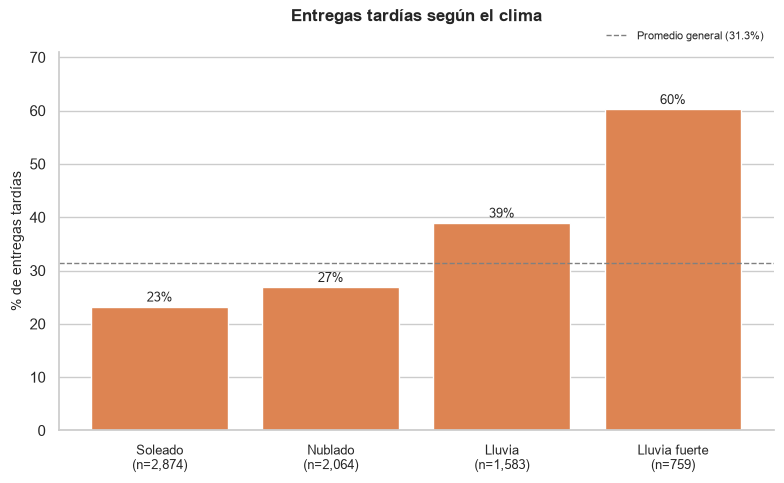

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
tasa_por("clima", ax, orden=["Soleado", "Nublado", "Lluvia", "Lluvia fuerte"], titulo="Entregas tardías según el clima")
plt.tight_layout()
plt.show()

El clima funciona como una escalera porque con sol 23 % y nublado 27 % los retrasos están por debajo del promedio, con lluvia suben a 39 % y con lluvia fuerte a 60 %. Es decir, una lluvia fuerte multiplica por 2,6 el riesgo frente a un día soleado. Los pedidos sin dato de clima 9 % no aparecen en esta gráfica, su tasa de retraso 30 % es parecida al promedio.

### Gráfica 5 · Hora de salida

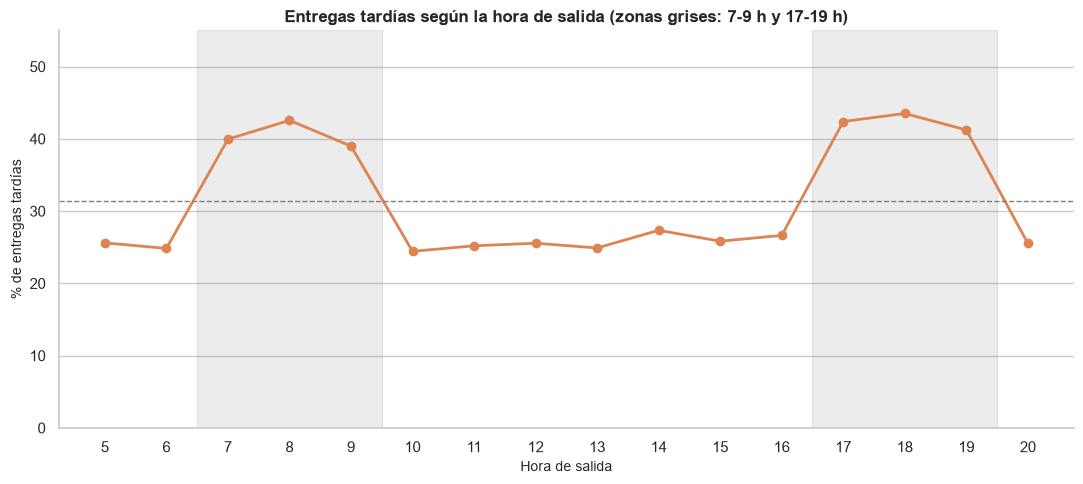

,% tardías,pedidos
Fuera de pico,25.59,4865
Hora pico (7-9 y 17-19),41.50,2805


In [30]:
por_hora = df_eda.groupby("hora_salida")["tardia"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(por_hora.index, por_hora["mean"] * 100, marker="o", color=COL_SI, lw=2)
ax.axhline(TASA_GLOBAL * 100, color="gray", ls="--", lw=1)
ax.axvspan(6.5, 9.5, color="gray", alpha=.15)
ax.axvspan(16.5, 19.5, color="gray", alpha=.15)
ax.set_xticks(range(5, 21))
ax.set_xlabel("Hora de salida")
ax.set_ylabel("% de entregas tardías")
ax.set_title("Entregas tardías según la hora de salida (zonas grises: 7-9 h y 17-19 h)")
ax.set_ylim(0, 55)
plt.tight_layout()
plt.show()

hora_pico = df_eda["hora_salida"].between(7, 9) | df_eda["hora_salida"].between(17, 19)
comp_pico = df_eda[df_eda["hora_salida"].notna()].groupby(hora_pico)["tardia"].agg(["mean", "size"])
comp_pico.index = ["Fuera de pico", "Hora pico (7-9 y 17-19)"]
comp_pico.columns = ["% tardías", "pedidos"]
comp_pico["% tardías"] *= 100
comp_pico

Esta nos parece  la gráfica más interesante, porque muestra por qué el enunciado advierte sobre la hora, el efecto no es lineal. Hay dos bloques claramente peores, de 7 a 9 h y de 17 a 19 h, donde los retrasos llegan a 40-44 %. Fuera de esos bloques la tasa se mantiene plana, entre 25 y 27 %. Corresponde a las horas pico de tráfico de la mañana y de la tarde. Agrupando, los despachos en hora pico tienen 41,5 % de retraso frente a 25,6 % los demás. Esto explica algo que veremos en la correlación y es que  si miramos la hora como número de 5 a 20, parece que no se relaciona con el retraso el efecto "sube y baja" y se cancela, pero sí influye mucho.

### Gráfica 6 · Experiencia del conductor y edad del vehículo

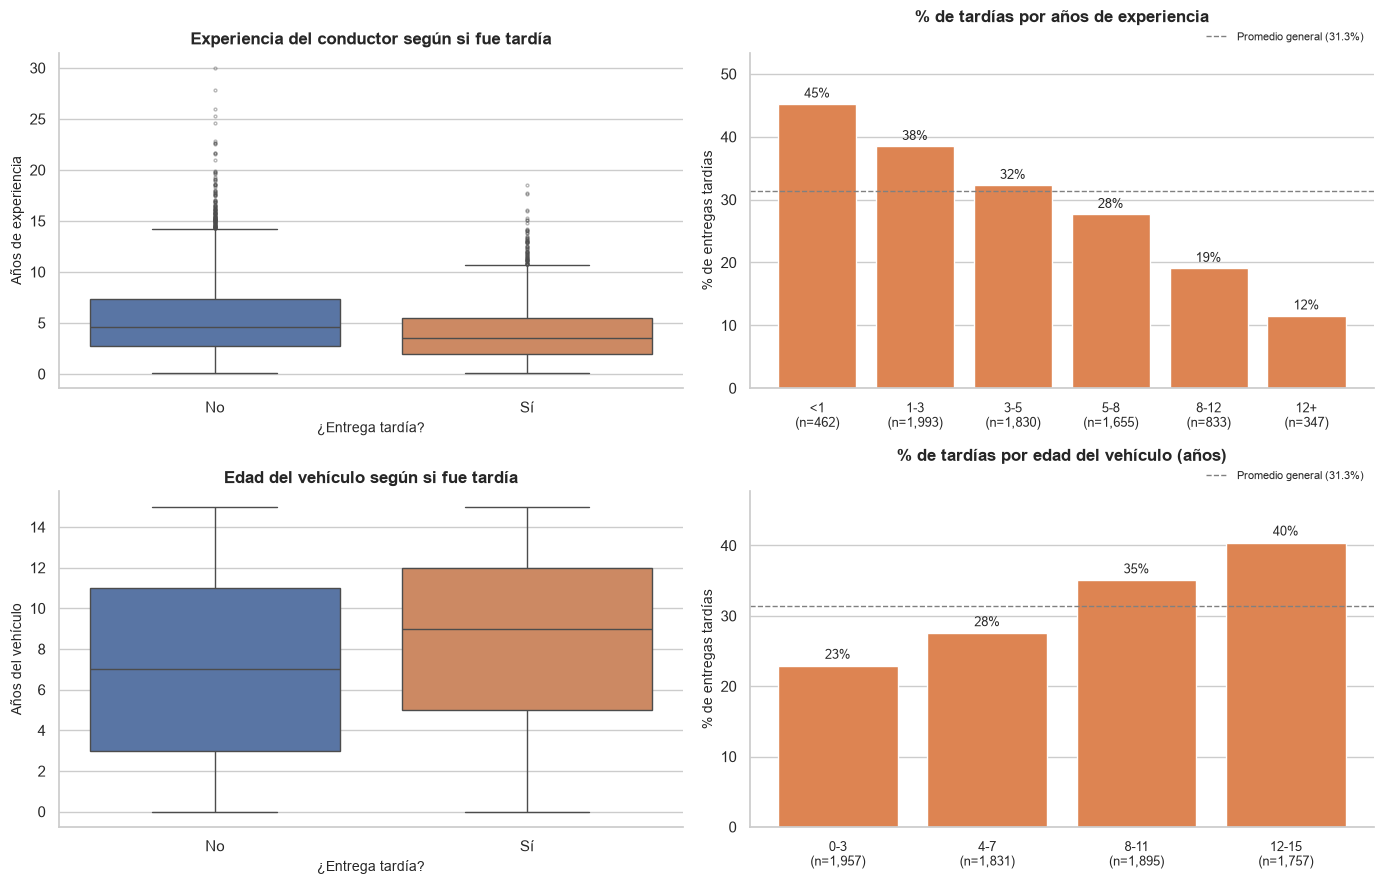

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

caja_por_objetivo("experiencia_conductor_anios", axes[0, 0], "Experiencia del conductor según si fue tardía")
axes[0, 0].set_ylabel("Años de experiencia")
bins = [0, 1, 3, 5, 8, 12, 40]
etq = ["<1", "1-3", "3-5", "5-8", "8-12", "12+"]
df_eda["rango_exp"] = pd.cut(df_eda["experiencia_conductor_anios"], bins=bins, labels=etq)
tasa_por("rango_exp", axes[0, 1], orden=etq, titulo="% de tardías por años de experiencia")

caja_por_objetivo("edad_vehiculo_anios", axes[1, 0], "Edad del vehículo según si fue tardía")
axes[1, 0].set_ylabel("Años del vehículo")
bins = [-1, 3, 7, 11, 15]
etq = ["0-3", "4-7", "8-11", "12-15"]
df_eda["rango_edad"] = pd.cut(df_eda["edad_vehiculo_anios"], bins=bins, labels=etq)
tasa_por("rango_edad", axes[1, 1], orden=etq, titulo="% de tardías por edad del vehículo (años)")
plt.tight_layout()
plt.show()

Las dos variables tienen un efecto monótono, pero en direcciones opuestas:

- **Experiencia:** a más experiencia, menos retrasos. Los conductores con menos de un año tienen 45 % de pedidos tardíos, y los de más de 12 años solo 11,5 %. La mediana de las entregas tardías es de 3,5 años de experiencia frente a 4,6 de las puntuales.
- **Edad del vehículo:** a más antiguo el vehículo, más retrasos, de 23 % en vehículos de 0 a 3 años a 40 % en los de 12 a 15 años fallas, menos potencia, más mantenimiento.
Las dos son variables que la empresa sí puede controlar por que deciden a quién asigna y con qué vehículo.

### Gráfica 7 · Prioridad, vehículo, día de la semana y centro de distribución

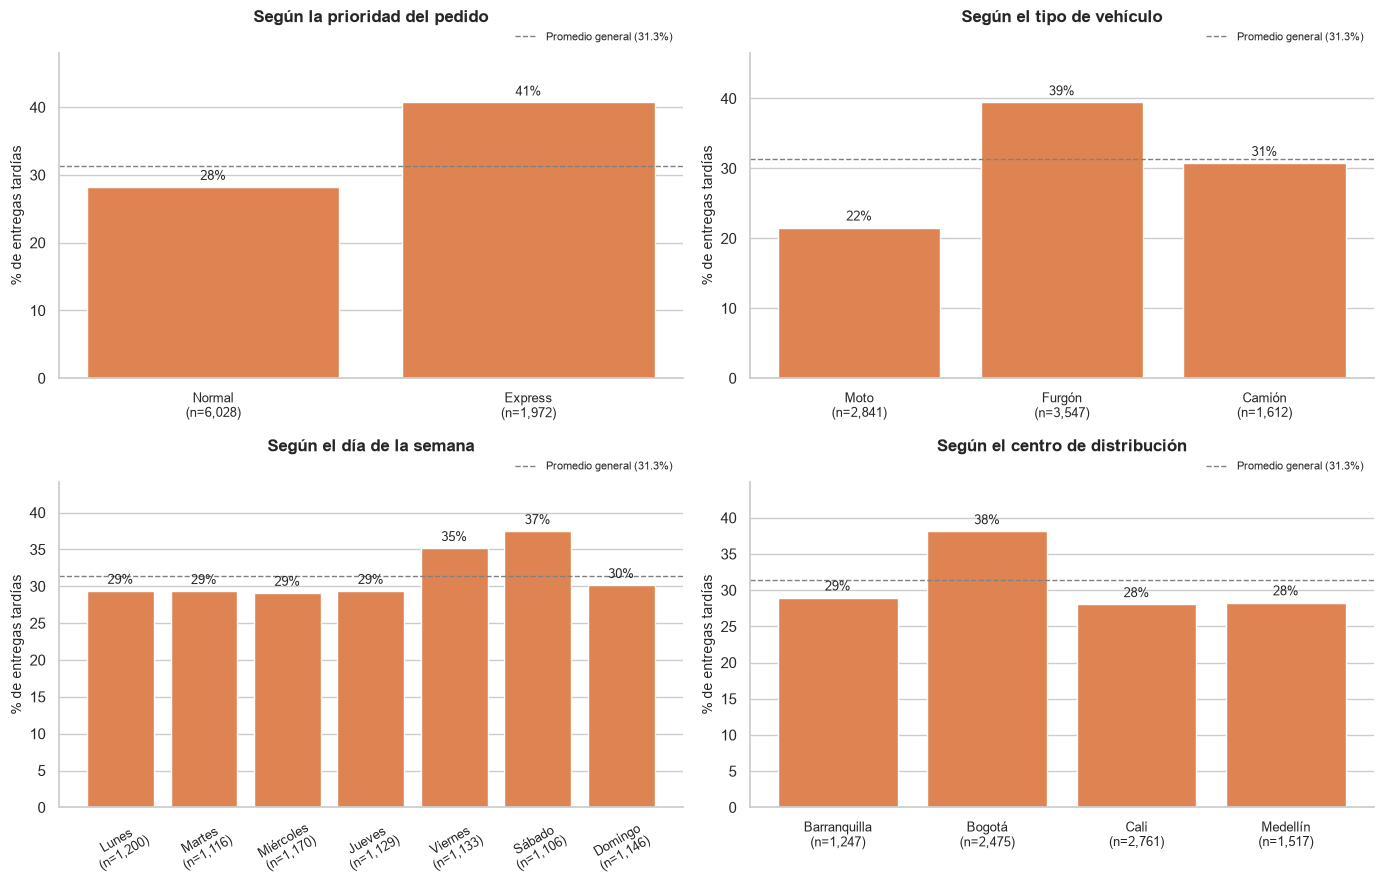

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
tasa_por("prioridad", axes[0, 0], orden=["Normal", "Express"], titulo="Según la prioridad del pedido")
tasa_por("tipo_vehiculo", axes[0, 1], orden=["Moto", "Furgón", "Camión"], titulo="Según el tipo de vehículo")
tasa_por("dia_semana", axes[1, 0], orden=orden_dias, titulo="Según el día de la semana", rot=30)
tasa_por("centro_distribucion", axes[1, 1], orden=["Barranquilla", "Bogotá", "Cali", "Medellín"], titulo="Según el centro de distribución")
plt.tight_layout()
plt.show()



- Los pedidos Express llegan tarde más que los normales 41 % frente a 28 % y tiene lógica, la ventana de entrega es más corta y por lo tanto es más fácil incumplirla.
- El furgón es el peor 39 %, seguido del camión 31 % y la moto 22 %. 
- De lunes a jueves y el domingo la tasa es casi igual 29-30 %, pero el viernes sube a 35 % y el sábado a 37 %.
- Bogotá se destaca con 38 % frente a 28-29 % de Barranquilla, Cali y Medellín. Es una diferencia de unos 10 puntos que vale la pena revisar con más detalle más adelante.

### Gráfica 8 · Peso, valor del pedido y tipo de cliente

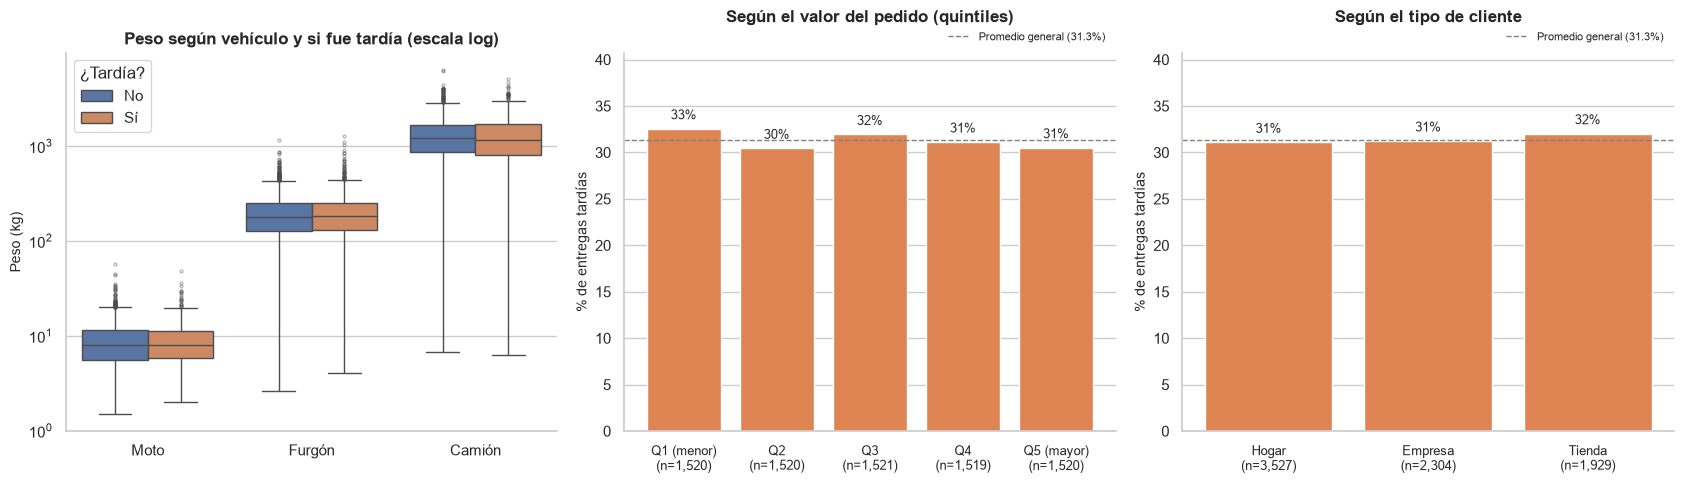

Peso mediano (kg) por vehículo y resultado:


entrega_tardia,No,Sí
tipo_vehiculo,,
Moto,8.00,7.90
Furgón,179.60,182.30
Camión,"1,220.70","1,163.55"


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Peso: lo miramos por tipo de vehículo, porque el peso cambia muchísimo de una moto a un camión
sns.boxplot(data=df_eda, x="tipo_vehiculo", y="peso_kg", hue=objetivo, order=["Moto", "Furgón", "Camión"],
            hue_order=["No", "Sí"], palette=PALETA, ax=axes[0], flierprops={"markersize": 2, "alpha": .4})
axes[0].set_yscale("log")
axes[0].set_title("Peso según vehículo y si fue tardía (escala log)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Peso (kg)")
axes[0].legend(title="¿Tardía?")

df_eda["rango_valor"] = pd.qcut(df_eda["valor_pedido_COP"], 5, labels=["Q1 (menor)", "Q2", "Q3", "Q4", "Q5 (mayor)"])
tasa_por("rango_valor", axes[1], titulo="Según el valor del pedido (quintiles)")
tasa_por("tipo_cliente", axes[2], orden=["Hogar", "Empresa", "Tienda"], titulo="Según el tipo de cliente")
plt.tight_layout()
plt.show()

print("Peso mediano (kg) por vehículo y resultado:")
df_eda.groupby(["tipo_vehiculo", objetivo])["peso_kg"].median().unstack().loc[["Moto", "Furgón", "Camión"]]

Estas tres variables prácticamente no distinguen entre pedidos puntuales y tardíos:

- Al mirarlo por tipo de vehículo, las cajas de "tardía" y "a tiempo" son casi idénticas, y las medianas casi iguales por ejemplo, en moto 8,0 kg vs. 7,9 kg. El peso parece relacionado con el retraso solo porque diferencia a los vehículos, pero dentro de cada vehículo no aporta casi nada.
- La tasa de retraso es casi igual en los cinco quintiles entre 30 % y 33 %. Que el pedido sea caro o barato no cambia la probabilidad de retraso.
- Hogar, empresa y tienda tienen prácticamente el mismo porcentaje 31-32 %.

Para el negocio  es útil saber que los retrasos no dependen de a quién se le entrega ni de cuánto vale el pedido, sino de cómo y por dónde se hace la ruta.

### Gráfica 9 · Interacciones: zona × clima y vehículo × zona

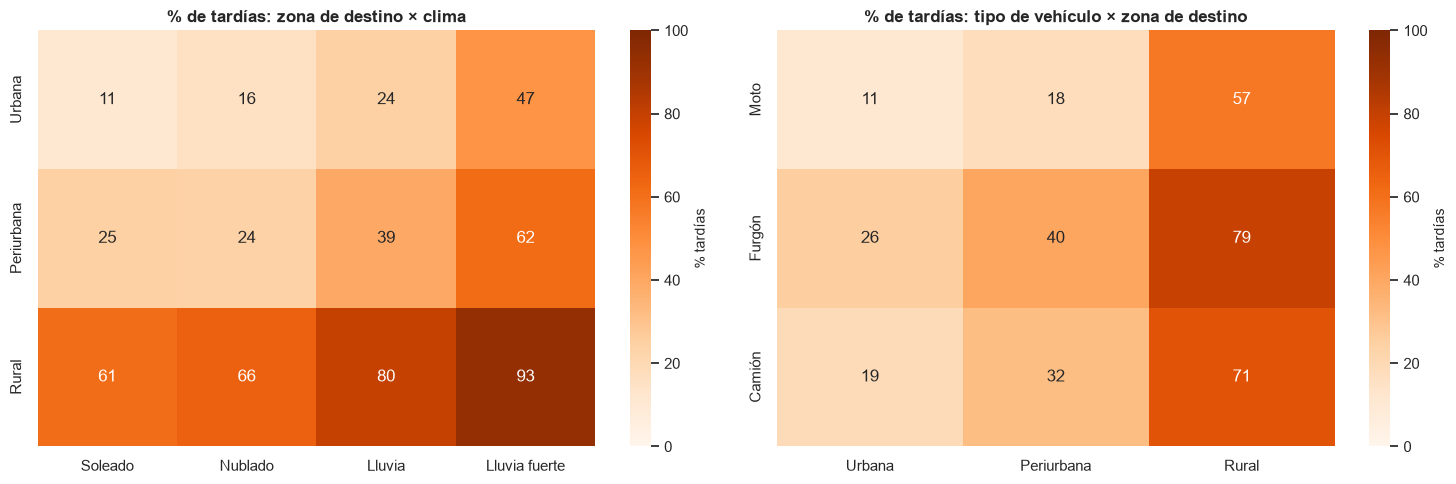

Composición de zonas dentro de cada vehículo (% de sus pedidos):


zona_destino,Urbana,Periurbana,Rural
tipo_vehiculo,,,
Moto,54.77,26.22,19.01
Furgón,53.37,29.12,17.51
Camión,56.58,27.42,16.00


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

p1 = df_eda.pivot_table(index="zona_destino", columns="clima", values="tardia", aggfunc="mean")
p1 = p1.loc[["Urbana", "Periurbana", "Rural"], ["Soleado", "Nublado", "Lluvia", "Lluvia fuerte"]] * 100
sns.heatmap(p1, annot=True, fmt=".0f", cmap="Oranges", vmin=0, vmax=100, ax=axes[0], cbar_kws={"label": "% tardías"})
axes[0].set_title("% de tardías: zona de destino × clima")
axes[0].grid(False)
axes[0].set_xlabel(""); axes[0].set_ylabel("")

p2 = df_eda.pivot_table(index="tipo_vehiculo", columns="zona_destino", values="tardia", aggfunc="mean")
p2 = p2.loc[["Moto", "Furgón", "Camión"], ["Urbana", "Periurbana", "Rural"]] * 100
sns.heatmap(p2, annot=True, fmt=".0f", cmap="Oranges", vmin=0, vmax=100, ax=axes[1], cbar_kws={"label": "% tardías"})
axes[1].set_title("% de tardías: tipo de vehículo × zona de destino")
axes[1].grid(False)
axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

print("Composición de zonas dentro de cada vehículo (% de sus pedidos):")
(pd.crosstab(df_eda["tipo_vehiculo"], df_eda["zona_destino"], normalize="index") * 100).loc[["Moto", "Furgón", "Camión"], ["Urbana", "Periurbana", "Rural"]]

Los mapas de calor cruzan dos variables a la vez, y muestran que los efectos se acumulan:

- Zona × clima: en zona urbana con sol solo llega tarde el 11 % de los pedidos, mientras que en zona rural con lluvia fuerte llega tarde el 93 %. La lluvia empeora las cosas en las tres zonas pero en la rural el punto de partida ya es malo 61 % incluso con sol.
- Vehículo × zona: el furgón es el peor en las tres zonas 26 %, 40 % y 79 %, el camión queda en medio y la moto es la mejor. La composición de zonas es casi igual para los tres vehículos alrededor de 54 % urbana, 28 % periurbana y 18 % rural, así que la diferencia no se debe a que los furgones vayan a lugares más difíciles. Lo que sí encontramos es que los furgones hacen muchas más paradas por ruta 8,9 en promedio contra 6,1 del camión y 4,0 de la moto, lo cual probablemente explica buena parte de su peor desempeño. Esto sugiere que los modelos de la siguiente fase deberían poder capturar combinaciones de variables y no solo efectos individuales.

### Gráfica 10 · ¿Cambia el retraso a lo largo del año?

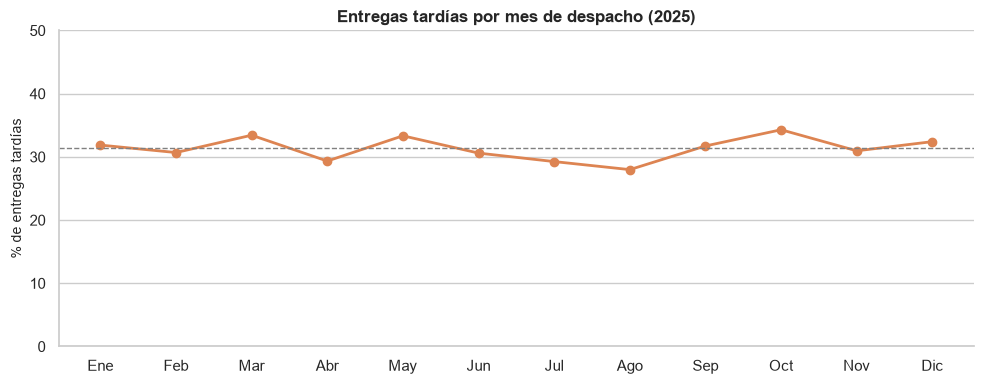

In [35]:
por_mes = df_eda.groupby("mes")["tardia"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(por_mes.index, por_mes["mean"] * 100, marker="o", color=COL_SI, lw=2)
ax.axhline(TASA_GLOBAL * 100, color="gray", ls="--", lw=1)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_ylim(0, 50)
ax.set_ylabel("% de entregas tardías")
ax.set_title("Entregas tardías por mes de despacho (2025)")
plt.tight_layout()
plt.show()

La tasa mensual se mueve entre 28 % y 34 % sin una tendencia ni una estacionalidad clara el mes más bajo es agosto y el más alto octubre. Con unos 600-700 pedidos por mes esas diferencias son parte del ruido normal. Descartamos que el retraso sea un problema que viene empeorando o que dependa de la época del año, por lo que la fecha no parece una variable útil para predecir.

### Resumen estadístico del análisis bivariado

Para no quedarnos solo con lo que se ve en las gráficas, hacemos una prueba estadística para cada variable frente al objetivo. En las categóricas, chi-cuadrado con la V de Cramér como medida del tamaño de la asociación y en las numéricas Mann-Whitney compara las dos distribuciones sin suponer que son normales, y como medida del tamaño usamos la correlación biserial por rangos. Un p-valor menor a 0,05 indica que la relación no parece producto del azar, el tamaño del efecto dice qué tan fuerte es. Las dos medidas de tamaño no son idénticas, pero ambas van de 0 a 1 y sirven para ordenar las variables.

In [ ]:
# Pruebas estadísticas para respaldar lo de las gráficas
def cramers_v(tabla):
    chi2 = stats.chi2_contingency(tabla)[0]
    n = tabla.values.sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

filas = []
for c in cat_cols:
    tabla = pd.crosstab(df_eda[c], df_eda[objetivo])
    chi2, p, gl, _ = stats.chi2_contingency(tabla)
    filas.append({"variable": c, "prueba": "Chi-cuadrado", "estadístico": chi2, "p-valor": p, "tamaño del efecto": cramers_v(tabla)})

for c in num_cols:
    a = df_eda.loc[df_eda[objetivo] == "Sí", c].dropna()
    b = df_eda.loc[df_eda[objetivo] == "No", c].dropna()
    u, p = stats.mannwhitneyu(a, b)
    r_bis = 2 * u / (len(a) * len(b)) - 1          # correlación biserial por rangos
    filas.append({"variable": c, "prueba": "Mann-Whitney", "estadístico": u, "p-valor": p, "tamaño del efecto": abs(r_bis)})

tests = pd.DataFrame(filas).set_index("variable").sort_values("tamaño del efecto", ascending=False)
tests["p-valor"] = tests["p-valor"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
tests["estadístico"] = tests["estadístico"].map(lambda v: f"{v:,.1f}")
tests["tamaño del efecto"] = tests["tamaño del efecto"].round(3)
tests

,prueba,estadístico,p-valor,tamaño del efecto
variable,,,,
distancia_km,Mann-Whitney,"8,984,145.5",< 0.001,0.45
zona_destino,Chi-cuadrado,"1,262.0",< 0.001,0.40
num_paradas,Mann-Whitney,"7,560,885.0",< 0.001,0.26
clima,Chi-cuadrado,443.4,< 0.001,0.25
experiencia_conductor_anios,Mann-Whitney,"4,258,649.5",< 0.001,0.22
edad_vehiculo_anios,Mann-Whitney,"7,066,294.0",< 0.001,0.19
tipo_vehiculo,Chi-cuadrado,235.2,< 0.001,0.17
peso_kg,Mann-Whitney,"6,512,834.5",< 0.001,0.13
prioridad,Chi-cuadrado,106.5,< 0.001,0.12


Los resultados confirman lo que vimos visualmente. Las variables más asociadas con el retraso son distancia y zona de destino, seguidas de número de paradas, clima, experiencia del conductor, edad del vehículo y tipo de vehículo. En un nivel más bajo están la prioridad, el centro de distribución y el día de la semana. Tres variables no muestran una relación relevante que son  el tipo de cliente p = 0,77 y el valor del pedido p = 0,49 no tienen asociación estadística, y la hora de salida sale con un efecto casi nulo 0,03 a pesar de la clara diferencia que vimos en hora pico. La razón es la que explicamos antes y es que la prueba compara los valores de la hora entre grupos, y como el efecto sube y baja durante el día, no lo detecta. Esto es una advertencia de que mirar solo estadísticos lineales puede hacernos descartar variables que en realidad son muy útiles.

## 6. Matriz de correlación

Calculamos la correlación de Pearson entre las variables numéricas, incluyendo la variable objetivo codificada como 0/1 `tardia`. Una correlación cercana a 1 o -1 indica una relación lineal fuerte, y cercana a 0, que no hay relación lineal.

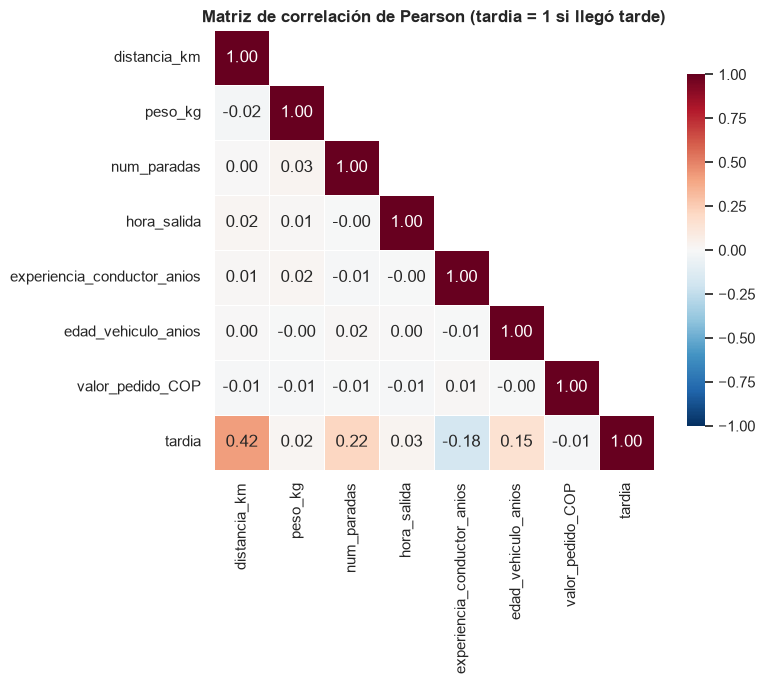

Mayor correlación (en valor absoluto) entre dos variables explicativas: 0.03


In [37]:
cols_corr = num_cols + ["tardia"]
corr = df_eda[cols_corr].corr()          # Pearson, con los nulos excluidos por pares

mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.5, square=True, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Matriz de correlación de Pearson (tardia = 1 si llegó tarde)")
ax.grid(False)
plt.tight_layout()
plt.show()

# ¿Qué tan correlacionadas están entre sí las variables explicativas?
entre_pred = corr.loc[num_cols, num_cols].where(~np.eye(len(num_cols), dtype=bool)).abs()
print(f"Mayor correlación (en valor absoluto) entre dos variables explicativas: {entre_pred.max().max():.2f}")

**Interpretación.**

- Distancia 0,42 es la variable más correlacionada con el retraso, y la relación es positiva, rutas más largas, más retrasos. Es una correlación moderada y es la más fuerte del conjunto.
- Número de paradas 0,22 también es positiva, más paradas, más retraso.
- Experiencia del conductor -0,18 es la única negativa de las relevantes, más experiencia, menos retrasos.
- Edad del vehículo 0,15 es positiva, vehículos más viejos se retrasan más.
- Peso 0,02, hora de salida 0,03 y valor del pedido -0,01 están prácticamente en cero.

Un detalle importante es que las variables explicativas no están correlacionadas entre sí la correlación más alta entre dos de ellas es 0,03. Esto es bueno, porque significa que cada una aporta información distinta y no hay problemas de multicolinealidad entre las numéricas. Pero la correlación de Pearson solo mide relaciones lineales, y ya vimos que dos de las variables con correlación casi nula sí tienen efecto, la hora con picos a las 7-9 y 17-19 h y el peso que depende del vehículo. Para mostrarlo calculamos también la correlación de Spearman y una versión de la hora convertida en "hora pico sí/no".

,Pearson,Spearman
distancia_km,0.42,0.36
num_paradas,0.22,0.21
experiencia_conductor_anios,-0.18,-0.17
hora_pico (7-9 y 17-19),0.17,0.17
edad_vehiculo_anios,0.15,0.15
hora_salida,0.03,0.03
peso_kg,0.02,0.10
valor_pedido_COP,-0.01,-0.01


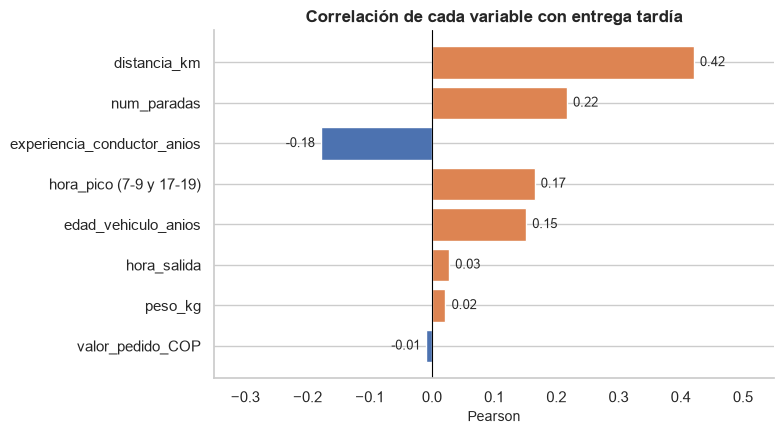

In [38]:
corr_obj = pd.DataFrame({
    "Pearson": df_eda[num_cols].corrwith(df_eda["tardia"], method="pearson"),
    "Spearman": df_eda[num_cols].corrwith(df_eda["tardia"], method="spearman"),
})

# Para mostrar el límite de la correlación lineal: hora_salida convertida a "hora pico sí/no"
pico = (df_eda["hora_salida"].between(7, 9) | df_eda["hora_salida"].between(17, 19)).astype(float)
pico[df_eda["hora_salida"].isna()] = np.nan
corr_obj.loc["hora_pico (7-9 y 17-19)"] = [pico.corr(df_eda["tardia"]), pico.corr(df_eda["tardia"], method="spearman")]
corr_obj = corr_obj.reindex(corr_obj["Pearson"].abs().sort_values(ascending=False).index)
display(corr_obj)

fig, ax = plt.subplots(figsize=(8, 4.5))
vals = corr_obj["Pearson"].iloc[::-1]
ax.barh(vals.index, vals.values, color=[COL_SI if v > 0 else COL_NO for v in vals.values])
ax.axvline(0, color="black", lw=.8)
for i, v in enumerate(vals.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(-0.35, 0.55)
ax.set_title("Correlación de cada variable con entrega tardía")
ax.set_xlabel("Pearson")
plt.tight_layout()
plt.show()

Al convertir la hora de salida en una variable de hora pico, la correlación pasa de 0,03 a 0,17, casi al nivel de la edad del vehículo. Quiere decir que la hora sí importa, pero hay que representarla de otra manera por ejemplo, una variable indicadora de hora pico para que un modelo lineal la aproveche.  Las correlaciones tampoco dicen nada de las variables categóricas zona, clima, vehículo, prioridad, centro, día, que ya vimos que tienen mucho peso. Por eso la correlación no es suficiente para el análisis y lo complementamos con las gráficas y pruebas mas adelante.

## 7. Balance de clases de la variable objetivo

Por último revisamos qué tan balanceada está la variable que queremos predecir. Es importante porque, si una clase es muy minoritaria, el accuracy puede dar una idea engañosa del modelo.

,pedidos,%
entrega_tardia,,
No,5493,68.66
Sí,2507,31.34


Razón entre clases: 2.19 pedidos a tiempo por cada pedido tardío
Accuracy de un 'modelo' que siempre responde 'No': 68.7%
En la base original (con duplicados) el % de tardías era 31.4%


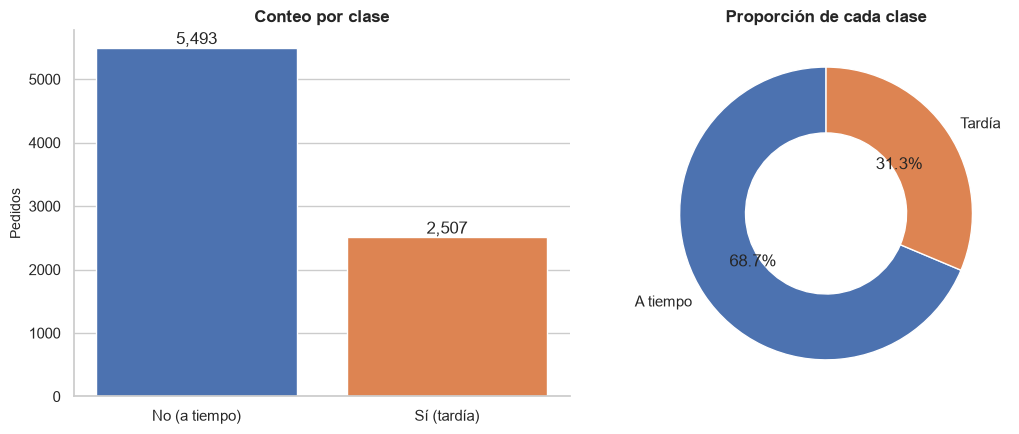

In [39]:
conteo = df_eda[objetivo].value_counts()
balance = pd.DataFrame({"pedidos": conteo, "%": conteo / conteo.sum() * 100}).loc[["No", "Sí"]]
display(balance)

razon = conteo["No"] / conteo["Sí"]
print(f"Razón entre clases: {razon:.2f} pedidos a tiempo por cada pedido tardío")
print(f"Accuracy de un 'modelo' que siempre responde 'No': {conteo['No'] / conteo.sum() * 100:.1f}%")
print(f"En la base original (con duplicados) el % de tardías era {(df[objetivo] == 'Sí').mean()*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(["No (a tiempo)", "Sí (tardía)"], conteo.loc[["No", "Sí"]], color=[COL_NO, COL_SI])
for i, v in enumerate(conteo.loc[["No", "Sí"]]):
    axes[0].text(i, v + 60, f"{v:,}", ha="center")
axes[0].set_ylabel("Pedidos")
axes[0].set_title("Conteo por clase")
axes[1].pie(conteo.loc[["No", "Sí"]], labels=["A tiempo", "Tardía"], colors=[COL_NO, COL_SI], autopct="%1.1f%%",
            startangle=90, wedgeprops={"width": .45, "edgecolor": "white"})
axes[1].set_title("Proporción de cada clase")
plt.tight_layout()
plt.show()

De los 8.000 pedidos únicos, 5.493 68,7 % llegaron a tiempo y 2.507 31,3 % llegaron tarde. Esto concuerda con lo que dice el enunciado "cerca de 3 de cada 10". Hay unos 2,2 pedidos puntuales por cada tardío. No es un desbalance extremo no es como un 95 % / 5 %, pero sí es suficiente para saber que toca tener cuidado, un modelo que siempre diga que el pedido llegará a tiempo ya tendría 68,7 % de accuracy sin aprender nada, y no detectaría ni un solo retraso. Por eso, en las siguientes fases el accuracy no puede ser la única métrica, habrá que mirar también recall, precision y F1 de la clase "tardía". También hay que acordarse de usar `stratify=y` al dividir en entrenamiento y prueba, para que las dos partes mantengan la misma proporción de 31 % de tardías.

## 8. Conclusiones del EDA

Las bases de datos presentan los problemas que anticipaba el enunciado. Hay nulos en 9 columnas, con afectaciones entre el 3 % y el 11 %, y el 44,7 % de las filas tiene al menos un nulo. También hay 35 filas duplicadas, que son copias exactas con el mismo ID. Las categorías mal escritas aparecen en la variable centro_distribucion, que pasa de 10 a 4 categorías, y en tipo_vehiculo, que pasa de 7 a 3. Además hay valores imposibles, como distancia menor o igual a 0 en 20 casos, hora mayor a 23 en 10, peso igual a 0 en 15, paradas igual a 0 en 59 y peso extremo para el vehículo en 31.

Lo que más se relaciona con el retraso, de más a menos, es lo siguiente. En primer lugar están la distancia y la zona de destino, que son los factores más fuertes, ya que la zona rural tiene 69 % de pedidos tardíos frente a 19 % en la urbana, y en las rutas de más de 100 km llega tarde el 86 %. En segundo lugar están el número de paradas, el clima y la experiencia del conductor, porque más paradas, lluvia, sobre todo fuerte, y conductores con poca experiencia aumentan el riesgo de forma clara. En tercer lugar están la edad del vehículo, el tipo de vehículo y la prioridad, con un efecto moderado, donde los furgones y los pedidos Express son los más expuestos. En cuarto lugar está la hora de salida, con un efecto fuerte pero no lineal, con picos entre las 7 y las 9 h y entre las 17 y las 19 h. En quinto lugar están el centro Bogotá y el día, viernes y sábado, con un efecto menor pero real. Por último, no tienen relación aparente el valor del pedido, el tipo de cliente, el peso dentro de cada vehículo y el mes del año.

Sobre el balance de clases, el 68,7 % de los pedidos llegó a tiempo y el 31,3 % llegó tarde, por lo que habrá que mirar el recall y el F1 de la clase tardía y no solo el accuracy. Lo que dejamos anotado para la Fase 3 es eliminar duplicados, unificar categorías, decidir qué hacer con los valores imposibles, que aquí los pasamos a nulo solo para graficar, tratar los nulos columna por columna, ya que no conviene borrar las filas porque serían casi la mitad de la base, y pensar cómo representar la hora de salida para que los modelos aprovechen el efecto de la hora pico.

Sobre las limitaciones de este análisis, las relaciones que encontramos son asociaciones y no demuestran causalidad, y por ejemplo el efecto del furgón puede venir de las paradas. Las gráficas por categoría se hicieron sin los nulos de cada variable, y el análisis univariado y bivariado se hizo con la copia de trabajo, que tiene una limpieza mínima y no definitiva.

---
# Fase 3 · Preparación de los datos

En la Fase 2 encontramos los problemas y aquí los vamos a resolver y justificamos cada decisión. El orden de lo que vamos a ahcer es:

1. Copia del DataFrame original  para no tocar los datos crudos.
2. Eliminar duplicados.
3. Estandarizar las categorías mal escritas.
4. Tratar los valores imposibles.
5. Tratar los nulos, columna por columna.
6. Crear la variable `hora_pico`.
7. Guardar la base limpia en CSV.
8. Codificar las categóricas con `get_dummies`.
9. Dividir en entrenamiento y prueba (70 % / 30 %, `stratify=y`, `random_state=42`).
10. Escalar (solo para la regresión logística).

Primero importamos lo que necesitamos de **scikit-learn** para las fases 3 a 5.

In [40]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEMILLA = 42   # la misma semilla en todo el notebook → resultados reproducibles
print("✅ Librerías de modelado cargadas")

✅ Librerías de modelado cargadas


## 3.1 Copia de trabajo y eliminación de duplicados

Partimos del `df` **original** (no de `df_eda`, que lo teniamos  solo para graficar). En la Fase 2 vimos que hay 35 filas que son copias exactas, con el mismo `id_pedido` y los mismos valores en todas las columnas. Si las dejamos, esos pedidos pesarían doble en el entrenamiento, y una copia podría quedar en train y su gemela en test, el modelo estaría viendo el examen antes de presentarlo. Por eso las eliminamos y dejamos solo una de cada par.

In [41]:
df_limpio = df.copy()   # tip de la profe: siempre trabajar sobre una copia

filas_antes = len(df_limpio)
df_limpio = df_limpio.drop_duplicates().reset_index(drop=True)

print(f"Filas antes: {filas_antes:,} → después: {len(df_limpio):,} (se eliminaron {filas_antes - len(df_limpio)} duplicados)")
print(f"IDs de pedido repetidos que quedan: {df_limpio['id_pedido'].duplicated().sum()}")

Filas antes: 8,035 → después: 8,000 (se eliminaron 35 duplicados)
IDs de pedido repetidos que quedan: 0


## 3.2 Estandarizar categorías mal escritas

Usamos la función `normalizar()` de la Fase 2 (quita espacios con `.str.strip()`, pasa a minúscula con `.str.lower()` y quita tildes) y luego un diccionario (`.map()`) que devuelve cada valor a su nombre oficial: `CALI `, `cali` y `Cali` → `Cali`. 

A las demás categóricas también les aplicamos `.str.strip()` por no dejar por que igual en la Fase 2 vimos que estaban bien escritas.

In [42]:
df_limpio["centro_distribucion"] = normalizar(df_limpio["centro_distribucion"]).map(mapa_centro)
df_limpio["tipo_vehiculo"] = normalizar(df_limpio["tipo_vehiculo"]).map(mapa_veh)

for c in ["dia_semana", "zona_destino", "clima", "tipo_cliente", "prioridad", "entrega_tardia"]:
    df_limpio[c] = df_limpio[c].str.strip()

# Verificación: ¿quedó algún valor sin traducir? (.map deja NaN si no encuentra la llave)
print("Valores que .map() no pudo traducir:",
      df_limpio["centro_distribucion"].isna().sum() + df_limpio["tipo_vehiculo"].isna().sum())
print()
for c in ["centro_distribucion", "tipo_vehiculo"]:
    print(df_limpio[c].value_counts().to_string(), end="\n\n")

Valores que .map() no pudo traducir: 0

centro_distribucion
Cali            2761
Bogotá          2475
Medellín        1517
Barranquilla    1247

tipo_vehiculo
Furgón    3547
Moto      2841
Camión    1612



Ahora hay exactamente 4 centros y 3 tipos de vehículo, como dice el enunciado, y ningún valor se perdió en la traducción.

## 3.3 Valores imposibles

En la Fase 2 definimos cinco reglas. Para cada una hay que decidir: ¿si se puede corregir el dato o hay que convertirlo a nulo (y luego imputarlo )? No eliminamos filas, porque el resto de la información del pedido sí es válida.

### a) Distancias negativas: ¿error de signo?
El enunciado menciona "errores de signo". Si eso es lo que pasó, el valor absoluto de la distancia negativa debería parecerse a las distancias normales de su misma zona. Lo  vamos a comprobar:

In [43]:
negativas = df_limpio[df_limpio["distancia_km"] <= 0]

evidencia = pd.DataFrame({
    "filas con distancia ≤ 0": negativas.groupby("zona_destino").size(),
    "mediana |distancia| de esas filas": negativas["distancia_km"].abs().groupby(negativas["zona_destino"]).median(),
    "mediana de las distancias válidas": df_limpio[df_limpio["distancia_km"] > 0].groupby("zona_destino")["distancia_km"].median(),
}).loc[["Urbana", "Periurbana", "Rural"]]
evidencia

,filas con distancia ≤ 0,mediana |distancia| de esas filas,mediana de las distancias válidas
zona_destino,,,
Urbana,11,14.90,11.80
Periurbana,6,46.30,34.40
Rural,3,118.10,85.80


La evidencia apoya el error de signo porque  en zona urbana el valor absoluto de las distancias negativas tiene mediana de 15 km (las válidas 12 km), en periurbana 46 km ( las válidas: 34 km) y en rural 118 km ( las válidas: 86 km). Los valores caen dentro del rango normal de su zona. Además, ninguna distancia es exactamente 0 todas son negativas.

**Decisión:** en vez de botar el dato, lo corregimos con el valor absoluto (`.abs()`). Así no perdemos información de 20 pedidos.

### b) Hora > 23, peso = 0, paradas = 0 y pesos extremos para el vehículo
Aquí no hay una forma confiable de saber cuál era el valor real (¿una hora "25" era la 1 a. m., las 15 h o las 20 h?), así que los convertimos a nulo y en la siguiente sección los tratamos igual que los demás faltantes. Los pesos extremos son, por ejemplo, motos con cientos o miles de kilos, usamos la misma regla de la Fase 2 (más de 10 veces el rango intercuartílico por encima del Q3 de su propio vehículo), que solo marca casos claramente absurdos.

In [44]:
# a) error de signo → valor absoluto
df_limpio["distancia_km"] = df_limpio["distancia_km"].abs()

# b) valores que no se pueden recuperar → nulo
nulos_antes = df_limpio[num_cols].isna().sum()

df_limpio.loc[df_limpio["hora_salida"] > 23, "hora_salida"] = np.nan
df_limpio.loc[df_limpio["peso_kg"] == 0, "peso_kg"] = np.nan
df_limpio.loc[df_limpio["num_paradas"] == 0, "num_paradas"] = np.nan

q1_veh = df_limpio.groupby("tipo_vehiculo")["peso_kg"].transform(lambda g: g.quantile(0.25))
q3_veh = df_limpio.groupby("tipo_vehiculo")["peso_kg"].transform(lambda g: g.quantile(0.75))
peso_absurdo = df_limpio["peso_kg"] > q3_veh + 10 * (q3_veh - q1_veh)
print("Ejemplos de pesos absurdos para su vehículo:")
display(df_limpio.loc[peso_absurdo, ["id_pedido", "tipo_vehiculo", "peso_kg"]].sort_values("peso_kg", ascending=False).head(6))
df_limpio.loc[peso_absurdo, "peso_kg"] = np.nan

cambio = pd.DataFrame({"nulos antes": nulos_antes, "nulos después": df_limpio[num_cols].isna().sum()})
cambio["valores imposibles → nulo"] = cambio["nulos después"] - cambio["nulos antes"]
cambio[cambio["valores imposibles → nulo"] > 0]

Ejemplos de pesos absurdos para su vehículo:


,id_pedido,tipo_vehiculo,peso_kg
79,P-05546,Furgón,"2,166.70"
6434,P-07708,Furgón,"1,930.50"
6744,P-00472,Moto,"1,914.60"
1045,P-01315,Furgón,"1,801.40"
7341,P-07628,Moto,"1,664.10"
1652,P-02431,Furgón,"1,612.10"


,nulos antes,nulos después,valores imposibles → nulo
peso_kg,640,686,46
num_paradas,480,539,59
hora_salida,320,330,10


Valores raros que NO tocamos son  las distancias de más de 200 km (todas en zona rural), los pedidos de más de 2 millones de pesos, conductores con 25 o más años de experiencia y vehículos de 0 años. Son poco frecuentes pero posibles; si los quitáramos estaríamos borrando justamente los casos más difíciles (las rutas rurales largas), que son los que más nos interesa predecir.

## 3.4 Tratamiento de nulos, columna por columna

Recordemos que:
- Si borráramos las filas con algún nulo perderíamos 45 % de la base  entonces eso esta descartado.
- Las filas con dato faltante se retrasan casi igual que el resto (31 %) , los nulos parecen ocurrir al azar, así que imputar no debería sesgar la relación con el objetivo.
- Varias variables son asimétricas (distancia, peso, experiencia, valor) , la mediana representa mejor al pedido típico que la media, porque no se deja jalar por los valores extremos.

Además, para dos variables usamos una mediana por grupo, porque la Fase 2 mostró que dependen fuertemente de otra columna que sí está completa

In [45]:
print("Mediana de la distancia por zona (km):")
print(df_limpio.groupby("zona_destino")["distancia_km"].median().loc[["Urbana", "Periurbana", "Rural"]].round(1).to_string())
print()
print("Mediana del peso y de las paradas por vehículo:")
print(df_limpio.groupby("tipo_vehiculo")[["peso_kg", "num_paradas"]].median().loc[["Moto", "Furgón", "Camión"]].round(1).to_string())
print()
print(f"Mediana general de la distancia: {df_limpio['distancia_km'].median():.1f} km | del peso: {df_limpio['peso_kg'].median():.1f} kg")

Mediana de la distancia por zona (km):
zona_destino
Urbana       11.80
Periurbana   34.40
Rural        86.00

Mediana del peso y de las paradas por vehículo:
               peso_kg  num_paradas
tipo_vehiculo                      
Moto              8.00         4.00
Furgón          180.40         9.00
Camión        1,207.40         6.00

Mediana general de la distancia: 19.5 km | del peso: 142.8 kg


Si a un pedido rural le faltara la distancia y le pusiéramos la mediana general (19 km), lo haríamos parecer un pedido urbano. Con la mediana de su zona (86 km) queda mucho más realista. Lo mismo con el peso, la mediana general (143 kg) no se parece ni a una moto (8 kg) ni a un camión (1.200 kg).

| Columna | % nulos (aprox.) | Estrategia | Por qué |
|---|---|---|---|
| `distancia_km` | 5 % | Mediana de su zona de destino | La distancia depende mucho de la zona (12 / 34 / 86 km) y la zona está completa. Es la variable más importante, así que vale la pena imputarla bien. |
| `peso_kg` | 8 % + valores imposibles | Mediana de su tipo de vehículo | El peso son tres poblaciones distintas (moto, furgón, camión). |
| `num_paradas` | 6 % + paradas = 0 | Mediana de su tipo de vehículo | Los furgones hacen muchas más paradas (9) que las motos (4). |
| `hora_salida` | 4 % + horas > 23 | Mediana general (12 h) | La hora es casi uniforme entre 5 y 20 h, así que no hay un grupo que la explique; la mediana deja el pedido en una hora "neutral". |
| `experiencia_conductor_anios` | 11 % | Mediana general | Asimétrica a la derecha (media > mediana); la mediana no se deja jalar por los pocos conductores muy veteranos. |
| `edad_vehiculo_anios` | 7 % | Mediana general | Distribución casi uniforme; media y mediana son casi iguales, elegimos la mediana por consistencia. |
| `valor_pedido_COP` | 5 % | Mediana general | Es la variable más asimétrica (asimetría 4,4); la media se infla con los pedidos de millones. |
| `clima` | 9 % | Nueva categoría "Sin dato" | Imputar la moda ("Soleado") sería decirle al modelo que esos pedidos tuvieron buen clima, y el clima es de las variables más importantes. Los pedidos sin clima se retrasan 30 %, que no se parece al soleado (23 %). Una categoría propia es más honesta. |
| `tipo_cliente` | 3 % | Moda ("Hogar") | Pocos nulos y la Fase 2 mostró que el tipo de cliente casi no se relaciona con el retraso, así que la moda no distorsiona. |

In [46]:
antes_imputar = df_limpio[num_cols].agg(["mean", "median"]).T   # para comparar después

# Mediana por grupo: .transform("median") devuelve, para cada fila, la mediana de SU grupo
df_limpio["distancia_km"] = df_limpio["distancia_km"].fillna(
    df_limpio.groupby("zona_destino")["distancia_km"].transform("median"))
for col in ["peso_kg", "num_paradas"]:
    df_limpio[col] = df_limpio[col].fillna(df_limpio.groupby("tipo_vehiculo")[col].transform("median"))

# Mediana general
for col in ["hora_salida", "experiencia_conductor_anios", "edad_vehiculo_anios", "valor_pedido_COP"]:
    df_limpio[col] = df_limpio[col].fillna(df_limpio[col].median())

# Categóricas
df_limpio["clima"] = df_limpio["clima"].fillna("Sin dato")
df_limpio["tipo_cliente"] = df_limpio["tipo_cliente"].fillna(df_limpio["tipo_cliente"].mode()[0])

print(f"Nulos que quedan en toda la base: {df_limpio.isna().sum().sum()}")

Nulos que quedan en toda la base: 0


Comprobamos que la imputación no cambió la forma de las variables la media y la mediana deberían moverse muy poco literal casi nada.

In [43]:
despues = df_limpio[num_cols].agg(["mean", "median"]).T
comparacion_imp = pd.concat([antes_imputar, despues], axis=1, keys=["Antes de imputar", "Después de imputar"])
comparacion_imp

Antes de imputar            Después de imputar           
                                        mean     median               mean     median
distancia_km                           34.39      19.50              34.25      19.30
peso_kg                               369.31     142.80             364.88     148.65
num_paradas                             6.61       6.00               6.60       6.00
hora_salida                            12.51      12.00              12.49      12.00
experiencia_conductor_anios             4.98       4.20               4.90       4.20
edad_vehiculo_anios                     7.36       7.00               7.33       7.00
valor_pedido_COP                  301,391.92 215,900.00         297,117.33 215,900.00

Las medianas quedan prácticamente iguales y las medias se mueven muy poco la del peso baja un poco porque quitamos las motos y furgones con pesos absurdos.Queda confirmado que  la imputación no deformó los datos.

## 3.5 Nueva variable: `hora_pico`

La profe nos dejó una pista: *"la hora de salida es numérica, pero quizás su efecto no es lineal"*. En la Fase 2 lo confirmamos: el retraso sube en dos bloques (7-9 h y 17-19 h) y es plano el resto del día, por eso la correlación de la hora con el retraso es casi 0 (0,03).

¿Cómo lo captura cada modelo?
- El **árbol de decisión** puede hacer cortes por rangos (`hora_salida <= 9.5`, `hora_salida > 16.5`…), así que puede encontrar los picos solo.
- La **regresión logística** solo dibuja relaciones del tipo "a más hora, más o menos riesgo". Con la hora como número no puede ver un efecto que sube y baja.

Por eso creamos una variable indicadora `hora_pico` (1 si sale entre 7-9 h o 17-19 h, 0 si no) y dejamos también `hora_salida` para que el árbol pueda usarla. 

In [47]:
df_limpio["hora_pico"] = (df_limpio["hora_salida"].between(7, 9) | df_limpio["hora_salida"].between(17, 19)).astype(int)
df_limpio["tardia"] = (df_limpio["entrega_tardia"] == "Sí").astype(int)   # objetivo en 0/1

tabla_pico = df_limpio.groupby("hora_pico")["tardia"].agg(["mean", "size"])
tabla_pico["mean"] = tabla_pico["mean"] * 100
tabla_pico.rename(index={0: "Fuera de pico", 1: "Hora pico"}, columns={"mean": "% tardías", "size": "pedidos"})

,% tardías,pedidos
hora_pico,,
Fuera de pico,25.85,5195
Hora pico,41.50,2805


## 3.6 Guardar la base limpia

Guardamos la base que usamos para modelar de 8.000 pedidos, sin duplicados, sin nulos, con las categorías unificadas y con `hora_pico` y `tardia`. 

In [45]:
df_limpio.to_csv("logistica_entregas_limpia.csv", index=False, encoding="utf-8-sig")
print(f"✅ Base limpia guardada: logistica_entregas_limpia.csv → {df_limpio.shape[0]:,} filas × {df_limpio.shape[1]} columnas")
df_limpio.head()

✅ Base limpia guardada: logistica_entregas_limpia.csv → 8,000 filas × 19 columnas


,id_pedido,fecha_despacho,dia_semana,centro_distribucion,zona_destino,tipo_vehiculo,distancia_km,peso_kg,num_paradas,hora_salida,clima,experiencia_conductor_anios,edad_vehiculo_anios,tipo_cliente,prioridad,valor_pedido_COP,entrega_tardia,hora_pico,tardia
0,P-04180,2025-10-24,Viernes,Cali,Rural,Furgón,58.90,115.50,10.00,19.00,Lluvia,5.70,9.00,Empresa,Normal,"193,700.00",Sí,1,1
1,P-00296,2025-11-19,Miércoles,Bogotá,Urbana,Furgón,25.70,264.30,9.00,17.00,Lluvia,3.20,4.00,Hogar,Normal,"361,300.00",Sí,1,1
2,P-02789,2025-02-23,Domingo,Medellín,Urbana,Moto,18.60,8.00,7.00,20.00,Soleado,4.20,5.00,Hogar,Express,"170,600.00",No,0,0
3,P-01284,2025-01-21,Martes,Bogotá,Urbana,Moto,5.10,9.20,1.00,6.00,Soleado,10.20,5.00,Empresa,Normal,"622,400.00",No,0,0
4,P-05152,2025-07-12,Sábado,Bogotá,Urbana,Furgón,14.20,260.50,1.00,5.00,Lluvia,6.50,15.00,Hogar,Normal,"406,500.00",No,0,0


## 3.7 Definir X e y, y codificar las categóricas

**Qué entra y qué no entra en X:**
- `id_pedido` no entra: es solo un código, no describe el pedido.
- `fecha_despacho` no entra: en la Fase 2 vimos que el retraso no cambia por mes, y una fecha de 2025 no le sirve al modelo para pedidos de 2026. El día de la semana sí entra, porque viernes y sábado son peores.
- `entrega_tardia` y `tardia` no entran: son la respuesta. Ponerlas en X sería fuga de datos.
- Todas las demás variables sí entran, porque se conocen al momento del despacho, que es cuando la gerencia quiere usar el modelo.

Los modelos solo entienden números, así que usamos `pd.get_dummies(..., drop_first=True)` como en clase. Antes ordenamos las categorías para que la que se elimina (la categoría de referencia) sea la más "normal" o de menor riesgo. Así, al leer los coeficientes de la logística, cada dummy se interpreta como "cuánto cambia el riesgo frente a la situación base":

| Variable | Referencia |
|---|---|
| zona_destino | Urbana |
| clima | Soleado |
| tipo_vehiculo | Moto |
| prioridad | Normal |
| centro_distribucion | Cali |
| dia_semana | Lunes |
| tipo_cliente | Hogar |

Metemos todo esto en una función `preparar_X()` para poder aplicar exactamente la misma transformación a pedidos nuevos en la Fase 5.

In [48]:
ORDEN_CATEGORIAS = {
    "zona_destino":        ["Urbana", "Periurbana", "Rural"],
    "clima":               ["Soleado", "Nublado", "Lluvia", "Lluvia fuerte", "Sin dato"],
    "tipo_vehiculo":       ["Moto", "Furgón", "Camión"],
    "prioridad":           ["Normal", "Express"],
    "centro_distribucion": ["Cali", "Bogotá", "Medellín", "Barranquilla"],
    "dia_semana":          ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"],
    "tipo_cliente":        ["Hogar", "Empresa", "Tienda"],
}
VARS_NUMERICAS = ["distancia_km", "peso_kg", "num_paradas", "hora_salida", "hora_pico",
                  "experiencia_conductor_anios", "edad_vehiculo_anios", "valor_pedido_COP"]

def preparar_X(datos):
    """Convierte la tabla de pedidos en la matriz numérica X que reciben los modelos."""
    X = datos[VARS_NUMERICAS + list(ORDEN_CATEGORIAS)].copy()
    for col, orden in ORDEN_CATEGORIAS.items():
        X[col] = pd.Categorical(X[col], categories=orden)   # fija el orden → la 1.ª es la referencia
    return pd.get_dummies(X, columns=list(ORDEN_CATEGORIAS), drop_first=True, dtype=int)

X = preparar_X(df_limpio)
y = df_limpio["tardia"]

print("Forma de X:", X.shape, "| Forma de y:", y.shape)
print("¿Se coló alguna columna prohibida en X?",
      any(c in X.columns for c in ["id_pedido", "fecha_despacho", "entrega_tardia", "tardia"]))
print()
print("Variables de entrada:")
print(list(X.columns))

Forma de X: (8000, 28) | Forma de y: (8000,)
¿Se coló alguna columna prohibida en X? False

Variables de entrada:
['distancia_km', 'peso_kg', 'num_paradas', 'hora_salida', 'hora_pico', 'experiencia_conductor_anios', 'edad_vehiculo_anios', 'valor_pedido_COP', 'zona_destino_Periurbana', 'zona_destino_Rural', 'clima_Nublado', 'clima_Lluvia', 'clima_Lluvia fuerte', 'clima_Sin dato', 'tipo_vehiculo_Furgón', 'tipo_vehiculo_Camión', 'prioridad_Express', 'centro_distribucion_Bogotá', 'centro_distribucion_Medellín', 'centro_distribucion_Barranquilla', 'dia_semana_Martes', 'dia_semana_Miércoles', 'dia_semana_Jueves', 'dia_semana_Viernes', 'dia_semana_Sábado', 'dia_semana_Domingo', 'tipo_cliente_Empresa', 'tipo_cliente_Tienda']


X queda con 8.000 pedidos y 28 variables: 8 numéricas (incluida `hora_pico`) y 20 dummies. Verificamos con código que ni el ID, ni la fecha, ni el objetivo están en X.

## 3.8 División en entrenamiento (70 %) y prueba (30 %)

Como pide el enunciado: `test_size=0.3`, `stratify=y` (ambas partes con la misma proporción de tardías, 31 %) y `random_state=42`.

In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEMILLA, stratify=y
)

print(f"Entrenamiento: {len(X_train):,} pedidos | % tardías: {y_train.mean()*100:.1f} %")
print(f"Prueba:        {len(X_test):,} pedidos | % tardías: {y_test.mean()*100:.1f} %")

Entrenamiento: 5,600 pedidos | % tardías: 31.3 %
Prueba:        2,400 pedidos | % tardías: 31.3 %


## 3.9 Escalado (solo para la regresión logística)

- La regresión logística necesita variables escaladas, la distancia va de 1 a 300, el valor del pedido de miles a millones y las dummies de 0 a 1. Sin escalar, el modelo converge mal y los coeficientes no se pueden comparar entre sí. Usamos `StandardScaler` (media 0, desviación 1).
- El árbol de decisión no lo necesita, solo hace preguntas del tipo "¿distancia ≤ 60?", y la respuesta es la misma en cualquier escala. Lo dejamos con las variables originales para que sus reglas se lean en km, años y horas.

 El escalador se ajusta **solo con train** (`fit_transform`) y al test solo se le aplica (`transform`). Si lo ajustáramos con toda la base, el modelo "vería" la media y la desviación del test → fuga de datos.

In [50]:
escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)   # aprende media y desviación SOLO de train
X_test_esc  = escalador.transform(X_test)        # aplica la misma transformación al test

print("Media de las 3 primeras columnas en train escalado:", X_train_esc[:, :3].mean(axis=0).round(2))
print("Desviación de las 3 primeras columnas en train escalado:", X_train_esc[:, :3].std(axis=0).round(2))

Media de las 3 primeras columnas en train escalado: [-0.  0. -0.]
Desviación de las 3 primeras columnas en train escalado: [1. 1. 1.]


---
# Fase 4 · Modelado

Vamos a entrenar  dos modelos de clasificación 

1. Árbol de decisión: fácil de explicar a la gerencia (son reglas de sí/no) y puede capturar efectos no lineales y combinaciones de variables.
2. Regresión logística: entrega una probabilidad de retraso para cada pedido y sus coeficientes dicen qué variables suben o bajan el riesgo.

Cómo elegimos los hiperparámetros sin hacer trampa, no podemos usar el test para escoger (sería como ver el parcial antes de presentarlo). Entonces usamos validación cruzada de 5 particiones sobre el entrenamiento, entrenamos 5 veces con 4/5 de los datos y evaluamos en el 1/5 restante. Como métrica de selección usamos el F1 de la clase "tardía": refleja nuestra prioridad (encontrar los retrasos, que pesa en el recall) sin premiar a un modelo que alerte todo (que tendría precision bajísima). También reportamos el recall de validación cruzada.

### Punto de partida: el "modelo flojo"
Antes de entrenar nada, ¿qué pasaría si dijéramos siempre "llegará a tiempo"? Ese es el mínimo que cualquier modelo tiene que superar.

In [51]:
pred_flojo = np.zeros(len(y_test), dtype=int)   # siempre "a tiempo"
print(f"Accuracy del modelo que siempre dice 'a tiempo': {accuracy_score(y_test, pred_flojo)*100:.1f} %")
print(f"Recall (tardías detectadas): {recall_score(y_test, pred_flojo)*100:.1f} %  → no detecta ni un solo retraso")

Accuracy del modelo que siempre dice 'a tiempo': 68.7 %
Recall (tardías detectadas): 0.0 %  → no detecta ni un solo retraso


## 4.1 Modelo A · Árbol de decisión

Probamos dos hiperparámetros a la vez:
- **`max_depth`** (3, 4, 5, 6, 8, 10 y sin límite): cuántos niveles de preguntas puede hacer el árbol. Más profundo = más detallado, pero más riesgo de memorizar.
- **`class_weight`** (`None` o `"balanced"`): con `"balanced"` le decimos al árbol que equivocarse con un pedido tardío pesa más ( 2,2 veces), porque es la clase minoritaria y la que más nos importa.

En total son 14 configuraciones.

In [52]:
resultados_arbol = []
for peso in [None, "balanced"]:
    for prof in [3, 4, 5, 6, 8, 10, None]:
        modelo = DecisionTreeClassifier(max_depth=prof, class_weight=peso, random_state=SEMILLA)
        f1_cv = cross_val_score(modelo, X_train, y_train, cv=5, scoring="f1").mean()
        rec_cv = cross_val_score(modelo, X_train, y_train, cv=5, scoring="recall").mean()
        modelo.fit(X_train, y_train)
        resultados_arbol.append({
            "class_weight": "balanced" if peso else "ninguno",
            "max_depth": "sin límite" if prof is None else prof,
            "F1 (CV)": f1_cv,
            "Recall (CV)": rec_cv,
            "Accuracy train": modelo.score(X_train, y_train),
            "Accuracy test": modelo.score(X_test, y_test),
        })

tabla_arbol = pd.DataFrame(resultados_arbol)
tabla_arbol["Brecha accuracy"] = tabla_arbol["Accuracy train"] - tabla_arbol["Accuracy test"]
tabla_arbol.round(3)

,class_weight,max_depth,F1 (CV),Recall (CV),Accuracy train,Accuracy test,Brecha accuracy
0,ninguno,3,0.56,0.46,0.78,0.76,0.02
1,ninguno,4,0.53,0.42,0.79,0.77,0.02
2,ninguno,5,0.56,0.46,0.80,0.78,0.02
3,ninguno,6,0.57,0.48,0.81,0.76,0.05
4,ninguno,8,0.58,0.51,0.85,0.78,0.08
5,ninguno,10,0.58,0.54,0.90,0.77,0.14
6,ninguno,sin límite,0.56,0.57,1.00,0.73,0.27
7,balanced,3,0.59,0.59,0.77,0.75,0.02
8,balanced,4,0.61,0.64,0.75,0.74,0.01
9,balanced,5,0.60,0.67,0.75,0.73,0.03


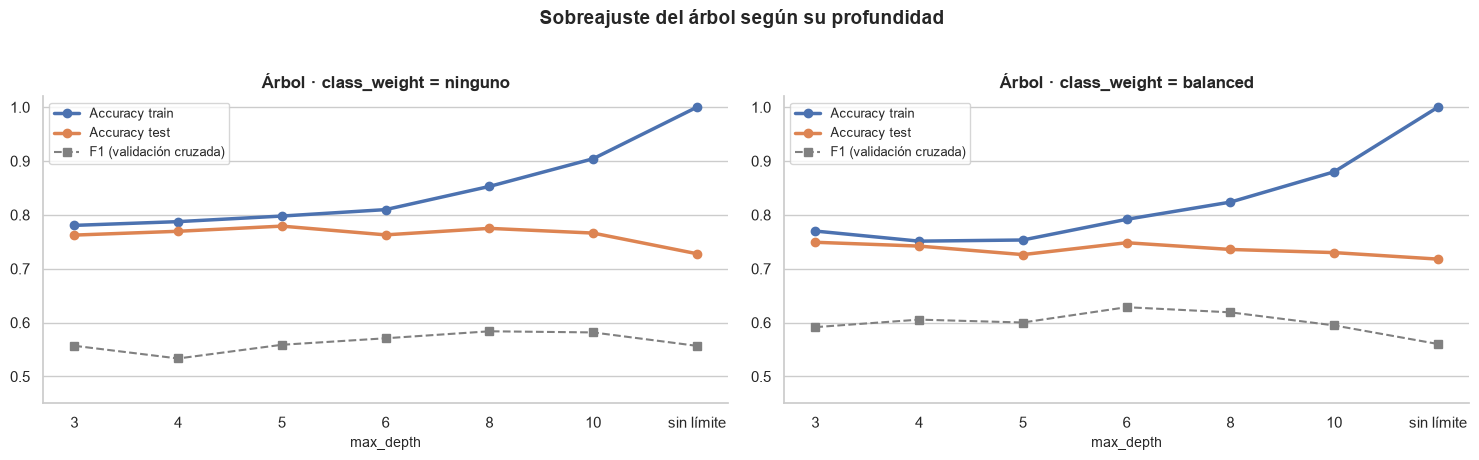

Configuración elegida por validación cruzada:
class_weight    balanced
max_depth              6
F1 (CV)             0.63
Recall (CV)         0.66


In [53]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=False)
for ax, peso in zip(axes, ["ninguno", "balanced"]):
    t = tabla_arbol[tabla_arbol["class_weight"] == peso]
    etiquetas_x = t["max_depth"].astype(str)
    ax.plot(etiquetas_x, t["Accuracy train"], marker="o", color=COL_NO, lw=2.5, label="Accuracy train")
    ax.plot(etiquetas_x, t["Accuracy test"], marker="o", color=COL_SI, lw=2.5, label="Accuracy test")
    ax.plot(etiquetas_x, t["F1 (CV)"], marker="s", color="gray", lw=1.5, ls="--", label="F1 (validación cruzada)")
    ax.set_title(f"Árbol · class_weight = {peso}")
    ax.set_xlabel("max_depth")
    ax.set_ylim(0.45, 1.02)
    ax.legend(loc="upper left", fontsize=9)
plt.suptitle("Sobreajuste del árbol según su profundidad", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

candidatos_arbol = tabla_arbol[tabla_arbol["max_depth"] != "sin límite"]
mejor_arbol = candidatos_arbol.loc[candidatos_arbol["F1 (CV)"].idxmax()]
print("Configuración elegida por validación cruzada:")
print(mejor_arbol[["class_weight", "max_depth", "F1 (CV)", "Recall (CV)"]].to_string())


- Sin límite de profundidad el árbol llega a 100 % de accuracy en entrenamiento pero cae a 73 % en prueba porque se aprendió de memoria los 5.600 pedidos de entrenamiento. Es sobreajuste puro, y queda casi al nivel del "modelo flojo" (68,7 %).
- A medida que sube `max_depth`, el accuracy de train sube siempre, pero el de test se queda quieto o baja y  la brecha crece. Es el sobreajuste apareciendo de a poquito.
- `class_weight="balanced"` mejora mucho el F1 y el recall en validación cruzada (el recall pasa de 45-55 % a 70 %). Sin balanceo, el árbol se "acomoda" diciendo "a tiempo" la mayoría de las veces.
- Elegimos la configuración con el mejor F1 en validación cruzada entre las que tienen profundidad controlada. La validación cruzada no mira el test, así que la elección es limpia.

In [54]:
prof_elegida = int(mejor_arbol["max_depth"])
peso_elegido = None if mejor_arbol["class_weight"] == "ninguno" else "balanced"

arbol = DecisionTreeClassifier(max_depth=prof_elegida, class_weight=peso_elegido, random_state=SEMILLA)
arbol.fit(X_train, y_train)

# Para la Fase 5 guardamos también el árbol SIN límite (para mostrar el sobreajuste)
arbol_libre = DecisionTreeClassifier(random_state=SEMILLA).fit(X_train, y_train)

print(f"✅ Árbol final: max_depth={prof_elegida}, class_weight={peso_elegido}")
print(f"   Hojas: {arbol.get_n_leaves()} (el árbol sin límite tiene {arbol_libre.get_n_leaves()} hojas y {arbol_libre.get_depth()} niveles)")

✅ Árbol final: max_depth=6, class_weight=balanced
   Hojas: 58 (el árbol sin límite tiene 898 hojas y 20 niveles)


### ¿Qué preguntas hace el árbol? (primeros 3 niveles)

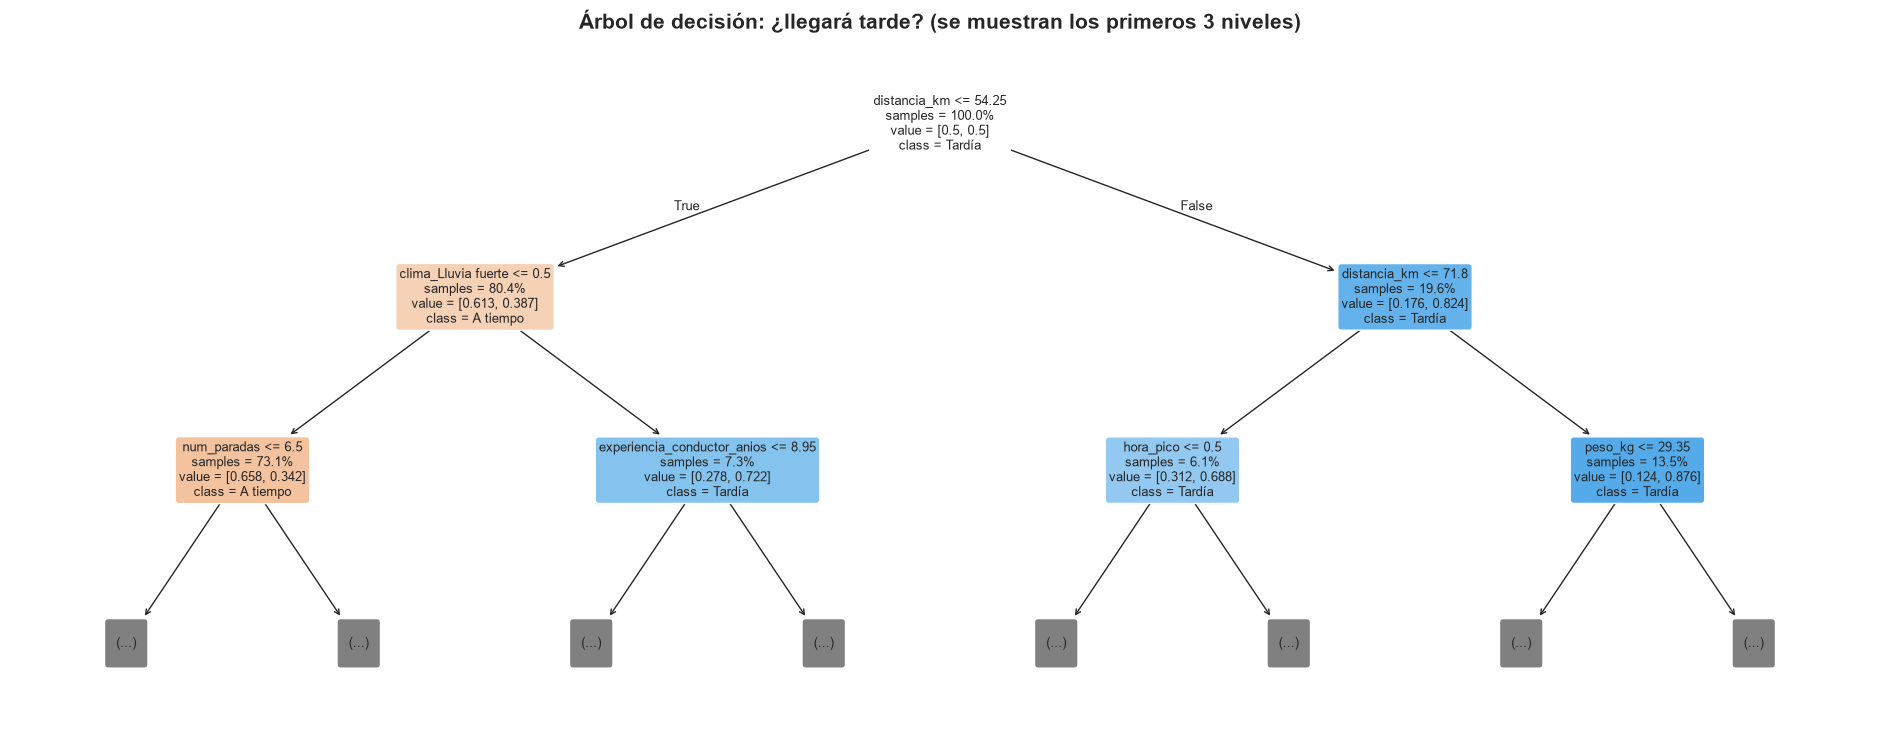

In [55]:
plt.figure(figsize=(24, 9))
plot_tree(arbol, feature_names=list(X.columns), class_names=["A tiempo", "Tardía"],
          filled=True, rounded=True, fontsize=9, max_depth=2, impurity=False, proportion=True)
plt.title("Árbol de decisión: ¿llegará tarde? (se muestran los primeros 3 niveles)", fontsize=15)
plt.show()

In [56]:
# Las reglas de los primeros niveles, en texto, para poder leerlas con calma
from sklearn.tree import export_text
print(export_text(arbol, feature_names=list(X.columns), max_depth=2, decimals=1))

|--- distancia_km <= 54.2
|   |--- clima_Lluvia fuerte <= 0.5
|   |   |--- num_paradas <= 6.5
|   |   |   |--- truncated branch of depth 4
|   |   |--- num_paradas >  6.5
|   |   |   |--- truncated branch of depth 4
|   |--- clima_Lluvia fuerte >  0.5
|   |   |--- experiencia_conductor_anios <= 8.9
|   |   |   |--- truncated branch of depth 4
|   |   |--- experiencia_conductor_anios >  8.9
|   |   |   |--- truncated branch of depth 4
|--- distancia_km >  54.2
|   |--- distancia_km <= 71.8
|   |   |--- hora_pico <= 0.5
|   |   |   |--- truncated branch of depth 4
|   |   |--- hora_pico >  0.5
|   |   |   |--- truncated branch of depth 4
|   |--- distancia_km >  71.8
|   |   |--- peso_kg <= 29.3
|   |   |   |--- truncated branch of depth 4
|   |   |--- peso_kg >  29.3
|   |   |   |--- truncated branch of depth 4



###  Interpretación de las primeras divisiones

Leemos el árbol de arriba hacia abajo (verdadero → izquierda, falso → derecha).

* scikit-learn pinta de naranja la clase "A tiempo" y de azul la clase "Tardía", al revés de nuestras gráficas. 
* Como el árbol usa `class_weight="balanced"`, el `value` de cada caja muestra proporciones ponderadas (por eso la raíz dice [0.5, 0.5] aunque solo el 31 % llega tarde). Por eso, abajo reportamos el % real de tardías de los pedidos de entrenamiento que caen en cada rama.

1. **¿la distancia es ≤ 54 km?** Es la división más importante de todo el árbol. El 80 % de los pedidos tiene rutas cortas y de ellos llega tarde el 22 %, en las rutas de más de 54 km llega tarde el 68 %. El árbol confirma lo que vimos en el EDA de que la distancia es el factor número uno.
2. Rutas cortas → ¿hay lluvia fuerte? Si no la hay, el árbol mira el número de paradas: con 6 o menos paradas solo llega tarde el 12 % y con 7 o más, el 27 %. Si hay lluvia fuerte, la pregunta es la experiencia del conductor: con 9 años o menos llega tarde el 59 %, y con más de 9 años solo el 15 % son pocos casos, pero la diferencia es enorme. En otras palabras, un conductor veterano neutraliza buena parte del efecto de la lluvia fuerte.
3. Rutas largas → ¿cuánto más larga? Entre 54 y 72 km, el árbol pregunta por la hora pico: fuera de pico llega tarde el 39 % y en hora pico el 68 %. Por encima de 72 km (rutas rurales) llega tarde el 76 %, y el árbol separa por peso: los pedidos de menos de 29 kg (que en la práctica son los que van en moto) se retrasan 61 %, y los más pesados (furgón y camión) 85 %.

Es justo lo que la profe nos sugería de que el árbol encontró solo los efectos no lineales (la hora pico) y las combinaciones (lluvia fuerte × experiencia, distancia × vehículo).


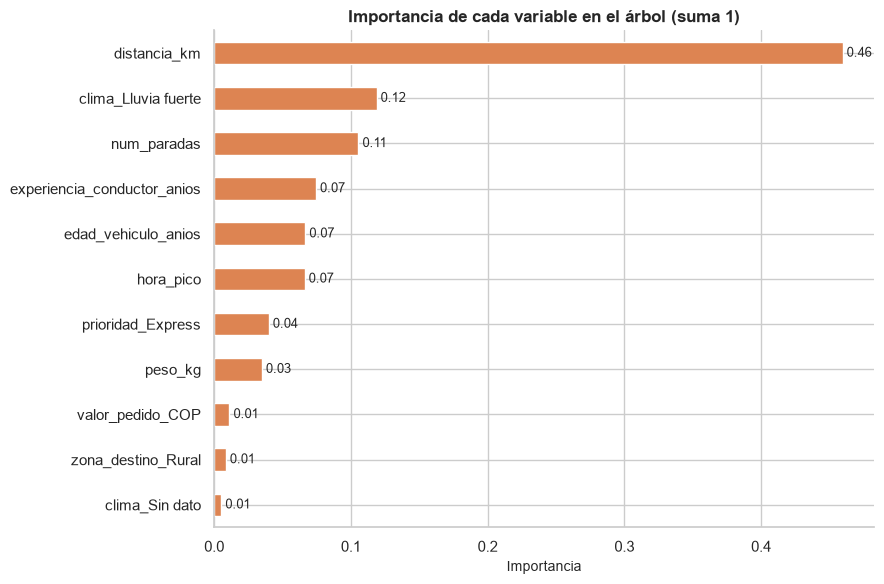

In [57]:
importancia = pd.Series(arbol.feature_importances_, index=X.columns).sort_values()
importancia = importancia[importancia > 0.005]

fig, ax = plt.subplots(figsize=(9, 6))
importancia.plot(kind="barh", color=COL_SI, ax=ax)
for i, v in enumerate(importancia.values):
    ax.text(v + 0.003, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_title("Importancia de cada variable en el árbol (suma 1)")
ax.set_xlabel("Importancia")
plt.tight_layout()
plt.show()


El árbol decide casi la mitad de todo con la distancia. Le siguen la lluvia fuerte , el número de paradas  , la experiencia del conductor, la edad del vehículo y la hora pico. Después vienen la prioridad Express y el peso.

Dos cosas curiosas:
- La zona de destino casi no aparece, aunque en el EDA era de las más fuertes. No es contradicción, la zona y la distancia cuentan casi la misma historia, rural = rutas largas, y como la distancia es más precisa, el árbol la prefiere. La información de la zona "ya está" dentro de la distancia.
- El valor del pedido, el tipo de cliente y el día de la semana prácticamente no se usan,  entonces es coherente con el EDA.


## 4.2 Modelo B · Regresión logística

La logística calcula una probabilidad de retraso entre 0 y 1 con la curva sigmoide:

$$P(\text{tardía}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n)}}$$

Si la probabilidad es mayor a 0,5, el modelo dice "tardía". Probamos dos hiperparámetros:
- **`class_weight`** (`None` o `"balanced"`), por la misma razón que en el árbol.
- **`C`** (0,01; 0,1; 1 y 10): controla la regularización. Un `C` pequeño obliga a los coeficientes a ser pequeños (modelo más simple y "prudente"); un `C` grande los deja libres. Es el equivalente a `max_depth` en el árbol: la perilla contra el sobreajuste.

En total son 8 configuraciones, todas con las variables escaladas.

In [58]:
resultados_log = []
for peso in [None, "balanced"]:
    for C in [0.01, 0.1, 1, 10]:
        modelo = LogisticRegression(C=C, class_weight=peso, max_iter=2000)
        f1_cv = cross_val_score(modelo, X_train_esc, y_train, cv=5, scoring="f1").mean()
        rec_cv = cross_val_score(modelo, X_train_esc, y_train, cv=5, scoring="recall").mean()
        modelo.fit(X_train_esc, y_train)
        resultados_log.append({
            "class_weight": "balanced" if peso else "ninguno",
            "C": C,
            "F1 (CV)": f1_cv,
            "Recall (CV)": rec_cv,
            "Accuracy train": modelo.score(X_train_esc, y_train),
            "Accuracy test": modelo.score(X_test_esc, y_test),
        })

tabla_log = pd.DataFrame(resultados_log)
tabla_log["Brecha accuracy"] = tabla_log["Accuracy train"] - tabla_log["Accuracy test"]
display(tabla_log.round(3))

mejor_log = tabla_log.loc[tabla_log["F1 (CV)"].idxmax()]
print("Configuración elegida por validación cruzada:")
print(mejor_log[["class_weight", "C", "F1 (CV)", "Recall (CV)"]].to_string())

,class_weight,C,F1 (CV),Recall (CV),Accuracy train,Accuracy test,Brecha accuracy
0,ninguno,0.01,0.68,0.59,0.83,0.83,0.00
1,ninguno,0.10,0.69,0.63,0.83,0.82,0.01
2,ninguno,1.00,0.69,0.63,0.83,0.82,0.01
3,ninguno,10.00,0.70,0.63,0.83,0.82,0.01
4,balanced,0.01,0.71,0.77,0.80,0.80,0.00
5,balanced,0.10,0.71,0.79,0.80,0.80,0.01
6,balanced,1.00,0.71,0.79,0.80,0.80,0.01
7,balanced,10.00,0.71,0.79,0.80,0.80,0.01


Configuración elegida por validación cruzada:
class_weight    balanced
C                   0.10
F1 (CV)             0.71
Recall (CV)         0.79



- En la logística la brecha entre train y test es mínima en todas las configuraciones menos de 1 punto, es un modelo simple que no tiende a sobreajustar con 5.600 pedidos y 28 variables.
- El valor de `C` cambia muy poco los resultados porque entre 0,1 y 10 son casi idénticos. Solo `C=0.01`, que restringe mucho los coeficientes, baja un poco el F1.
- Lo que sí marca la diferencia es `class_weight="balanced"` el recall en validación cruzada sube de 63 % a 78 % a cambio de algo de accuracy. Esto va en línea con lo que definimos al inicio.
- Elegimos la configuración con mejor F1 en la validación cruzada.

In [59]:
C_elegido = float(mejor_log["C"])
peso_log = None if mejor_log["class_weight"] == "ninguno" else "balanced"

logistica = LogisticRegression(C=C_elegido, class_weight=peso_log, max_iter=2000)
logistica.fit(X_train_esc, y_train)
print(f"✅ Regresión logística final: C={C_elegido}, class_weight={peso_log}")

✅ Regresión logística final: C=0.1, class_weight=balanced


### ¿Le sirvió a la logística la variable `hora_pico`?
Hacemos una prueba rápida: la misma logística, pero sin `hora_pico` (solo con la hora como número).

In [60]:
sin_pico = [c for c in X.columns if c != "hora_pico"]
esc_tmp = StandardScaler().fit(X_train[sin_pico])
log_sin_pico = LogisticRegression(C=C_elegido, class_weight=peso_log, max_iter=2000)
f1_sin = cross_val_score(log_sin_pico, esc_tmp.transform(X_train[sin_pico]), y_train, cv=5, scoring="f1").mean()

print(f"F1 (CV) de la logística CON hora_pico: {mejor_log['F1 (CV)']:.3f}")
print(f"F1 (CV) de la logística SIN hora_pico: {f1_sin:.3f}")

F1 (CV) de la logística CON hora_pico: 0.712
F1 (CV) de la logística SIN hora_pico: 0.699



Sin `hora_pico`, el F1 de la logística baja de 0,712 a 0,699. La diferencia es pequeña pero va en la dirección esperada como la logística solo ve relaciones "en línea recta", con la hora como número no puede capturar los dos picos del día. Al darle la variable indicadora, la hora pasa a ser una de sus variables más importantes, por eso vamos a dejar `hora_pico` en el modelo final.


### Coeficientes: ¿qué sube y qué baja el riesgo?
Como las variables están escaladas, los coeficientes sí se pueden comparar entre sí, un coeficiente más grande (en valor absoluto) significa más influencia. El signo dice la dirección:
- **Positivo (naranja)** → aumenta la probabilidad de llegar tarde.
- **Negativo (azul)** → la disminuye.

Para las dummies, el coeficiente se compara contra la categoría de referencia (por ejemplo, `clima_Lluvia fuerte` frente a un día soleado).

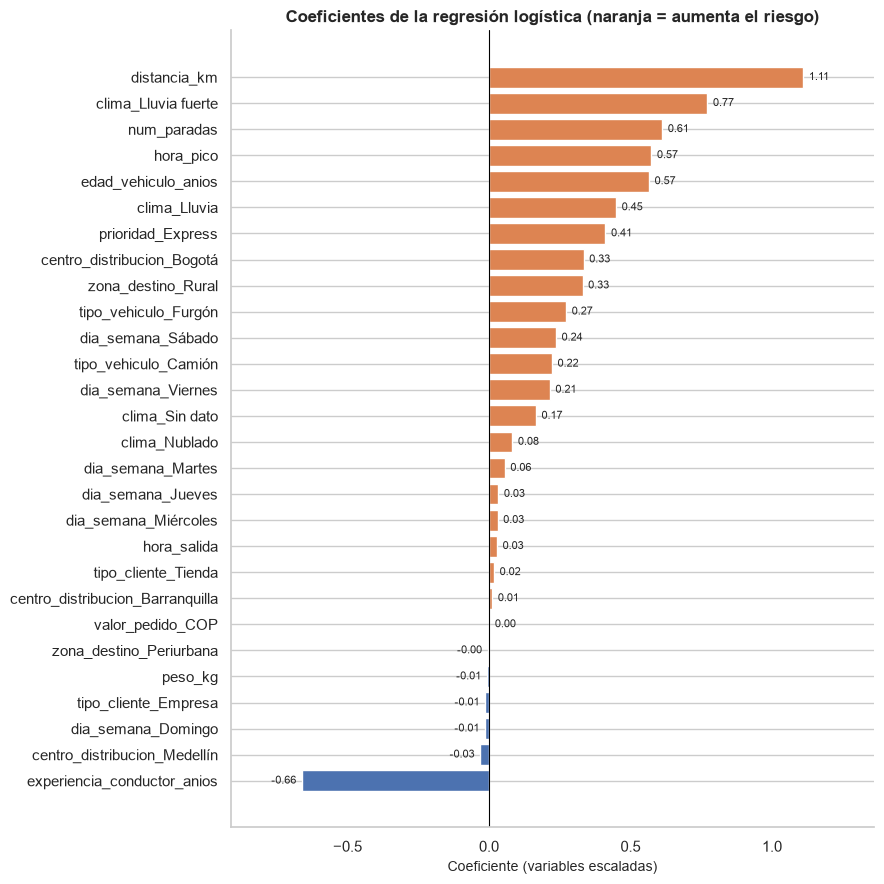

In [61]:
coef = pd.Series(logistica.coef_[0], index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(coef.index, coef.values, color=[COL_SI if v > 0 else COL_NO for v in coef.values])
ax.axvline(0, color="black", lw=0.8)
for i, v in enumerate(coef.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8)
ax.set_xlim(coef.min() - 0.25, coef.max() + 0.25)
ax.set_title("Coeficientes de la regresión logística (naranja = aumenta el riesgo)")
ax.set_xlabel("Coeficiente (variables escaladas)")
plt.tight_layout()
plt.show()


Lo que aumenta el riesgo de llegar tarde (de mayor a menor efecto):
1. **Distancia (+1,11)**: es por mucho el coeficiente más grande. Rutas más largas, más retraso.
2. **Lluvia fuerte (+0,77)** y **lluvia (+0,45)**, frente a un día soleado. Nublado (+0,08) casi no cambia nada.
3. **Número de paradas (+0,61)**.
4. **Hora pico (+0,57)**: salir entre 7-9 h o 17-19 h. Mientras tanto, `hora_salida` como número tiene un coeficiente casi nulo (+0,03): lo que importa no es "más tarde o más temprano", sino caer en el pico.
5. **Edad del vehículo (+0,57)**.
6. **Prioridad Express (+0,41)**: la ventana es más corta, así que es más fácil incumplirla.
7. **Centro Bogotá (+0,33)** frente a Cali, y **zona rural (+0,33)** frente a la urbana, incluso después de tener en cuenta la distancia.
8. **Furgón (+0,27)** y **camión (+0,22)** frente a la moto; **viernes (+0,21)** y **sábado (+0,24)** frente al lunes.

**Lo que disminuye el riesgo:**
- **Experiencia del conductor (−0,66)**: es el único coeficiente negativo importante, y es el tercero más grande en valor absoluto. Más años de experiencia, menos retrasos.

**Lo que no importa realmente:** el peso, el valor del pedido, el tipo de cliente, la zona periurbana (una vez se conoce la distancia), y los centros de Medellín y Barranquilla (se comportan igual que Cali): todos con coeficientes cercanos a 0.

Todo es coherente con el EDA y con el árbol, el retraso depende de cómo y por dónde se hace la ruta (distancia, paradas, hora, clima, conductor, vehículo), no de quién es el cliente ni cuánto vale el pedido.


---
# Fase 5 · Evaluación

## 5.1 Matriz de confusión y métricas de cada modelo (en prueba)

Para mayor facilidad recordemos qué responde cada métrica en nuestro caso:

| Métrica | Pregunta que responde |
|---|---|
| **Accuracy** | De todos los pedidos, ¿qué % clasificó bien? |
| **Precision** | De los pedidos que el modelo marcó como "tardía", ¿cuántos sí llegaron tarde? (¿sus alertas son confiables?) |
| **Recall** | De los pedidos que sí llegaron tarde, ¿cuántos detectó? (¿se le escapan retrasos?) |
| **F1** | Equilibrio entre precision y recall |

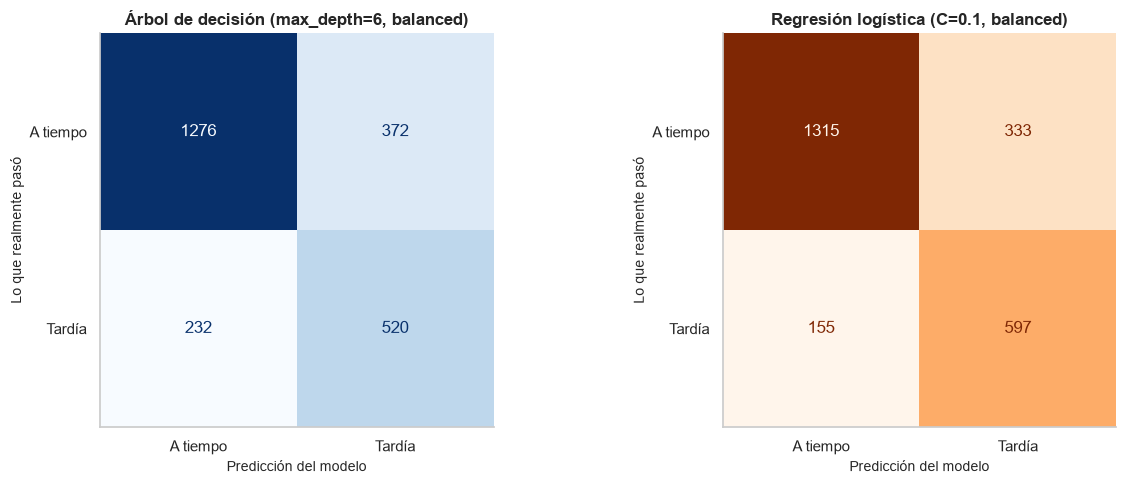

In [62]:
pred_arbol = arbol.predict(X_test)
pred_log = logistica.predict(X_test_esc)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_arbol, display_labels=["A tiempo", "Tardía"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Árbol de decisión (max_depth={prof_elegida}, {peso_elegido})")
ConfusionMatrixDisplay.from_predictions(y_test, pred_log, display_labels=["A tiempo", "Tardía"],
                                        cmap="Oranges", ax=axes[1], colorbar=False)
axes[1].set_title(f"Regresión logística (C={C_elegido}, {peso_log})")
for ax in axes:
    ax.grid(False)
    ax.set_xlabel("Predicción del modelo")
    ax.set_ylabel("Lo que realmente pasó")
plt.tight_layout()
plt.show()

In [63]:
print("=== ÁRBOL DE DECISIÓN ===")
print(classification_report(y_test, pred_arbol, target_names=["A tiempo", "Tardía"], digits=3))
print("=== REGRESIÓN LOGÍSTICA ===")
print(classification_report(y_test, pred_log, target_names=["A tiempo", "Tardía"], digits=3))

=== ÁRBOL DE DECISIÓN ===
              precision    recall  f1-score   support

    A tiempo      0.846     0.774     0.809      1648
      Tardía      0.583     0.691     0.633       752

    accuracy                          0.748      2400
   macro avg      0.715     0.733     0.721      2400
weighted avg      0.764     0.748     0.753      2400

=== REGRESIÓN LOGÍSTICA ===
              precision    recall  f1-score   support

    A tiempo      0.895     0.798     0.843      1648
      Tardía      0.642     0.794     0.710       752

    accuracy                          0.797      2400
   macro avg      0.768     0.796     0.777      2400
weighted avg      0.815     0.797     0.802      2400




En el conjunto de prueba hay 2.400 pedidos, de los cuales 752 llegaron tarde.

- Árbol de decisión: detecta 520 de los 752 pedidos tardíos (recall 0,69) y se le escapan 232. De los 892 pedidos que alerta, 520 sí llegaron tarde (precision 0,58), genera 372 falsas alarmas. F1 = 0,63 y accuracy = 74,8 %.
- Regresión logística: detecta 597 de los 752 (recall 0,79) y solo se le escapan 155. De los 930 pedidos que alerta, 597 sí llegaron tarde (precision 0,64), con 333 falsas alarmas. F1 = 0,71 y accuracy = 79,7 %.

La logística es mejor en todas las métricas de la clase "tardía": detecta 77 retrasos más que el árbol y, al mismo tiempo, da 39 falsas alarmas menos.


## 5.2 Entrenamiento vs. prueba: ¿hay sobreajuste?

Si un modelo es mucho mejor en entrenamiento que en prueba, memorizó en vez de aprender. Comparamos todas las métricas en las dos partes, e incluimos el árbol sin límite como ejemplo de lo que pasa cuando no se controla la profundidad.

In [64]:
def metricas(y_real, y_pred):
    return {"Accuracy": accuracy_score(y_real, y_pred),
            "Precision": precision_score(y_real, y_pred),
            "Recall": recall_score(y_real, y_pred),
            "F1": f1_score(y_real, y_pred)}

modelos_eval = {
    "Árbol sin límite (sobreajustado)": (arbol_libre, X_train, X_test),
    f"Árbol (max_depth={prof_elegida}, balanced)": (arbol, X_train, X_test),
    f"Regresión logística (C={C_elegido}, balanced)": (logistica, X_train_esc, X_test_esc),
}

filas = []
for nombre, (modelo, Xtr, Xte) in modelos_eval.items():
    m_train = metricas(y_train, modelo.predict(Xtr))
    m_test = metricas(y_test, modelo.predict(Xte))
    for met in m_train:
        filas.append({"Modelo": nombre, "Métrica": met, "Train": m_train[met], "Test": m_test[met]})

train_vs_test = pd.DataFrame(filas)
train_vs_test["Brecha (train − test)"] = train_vs_test["Train"] - train_vs_test["Test"]
train_vs_test.set_index(["Modelo", "Métrica"]).round(3)

Train  Test  Brecha (train − test)
Modelo                                Métrica                                      
Árbol sin límite (sobreajustado)      Accuracy    1.00  0.73                   0.27
                                      Precision   1.00  0.56                   0.43
                                      Recall      1.00  0.57                   0.43
                                      F1          1.00  0.57                   0.43
Árbol (max_depth=6, balanced)         Accuracy    0.79  0.75                   0.04
                                      Precision   0.65  0.58                   0.07
                                      Recall      0.73  0.69                   0.04
                                      F1          0.69  0.63                   0.05
Regresión logística (C=0.1, balanced) Accuracy    0.80  0.80                   0.01
                                      Precision   0.65  0.64                   0.01
                                      Recall      0.79  0.79                  -0.01
                                      F1          0.71  0.71                   0.00

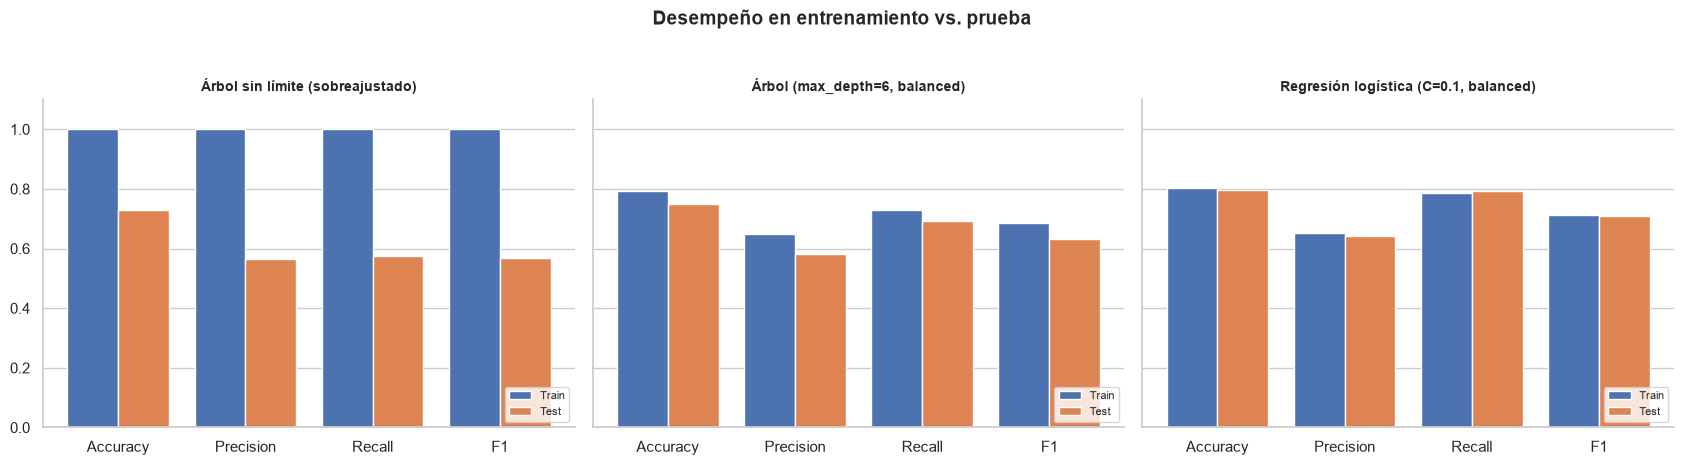

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, nombre in zip(axes, modelos_eval):
    t = train_vs_test[train_vs_test["Modelo"] == nombre]
    pos = np.arange(len(t))
    ax.bar(pos - 0.2, t["Train"], width=0.4, color=COL_NO, label="Train")
    ax.bar(pos + 0.2, t["Test"], width=0.4, color=COL_SI, label="Test")
    ax.set_xticks(pos)
    ax.set_xticklabels(t["Métrica"])
    ax.set_ylim(0, 1.1)
    ax.set_title(nombre, fontsize=10)
    ax.legend(fontsize=8, loc="lower right")
plt.suptitle("Desempeño en entrenamiento vs. prueba", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


- **Árbol sin límite:** el ejemplo de manual de sobreajuste. Acierta el 100 % en entrenamiento pero cae a 73 % en prueba, y su F1 pasa de 1,00 a 0,57 (brecha de 43 puntos). Creció hasta 20 niveles y casi 900 hojas: se aprendió de memoria los pedidos de entrenamiento, ruido incluido.
- **Árbol con `max_depth=6`:** la brecha baja a 4 puntos en accuracy y 5 en F1. Hay un sobreajuste leve (es normal que un árbol sea un poco mejor en lo que ya vio), pero está controlado. Limitar la profundidad fue lo que lo arregló.
- **Regresión logística:** las métricas de train y test son prácticamente iguales (brecha ≤ 1 punto en todas). No hay sobreajuste, lo que aprendió generaliza a pedidos que nunca vio. Esto también le da más confianza a la gerencia de que el desempeño se va a mantener con pedidos nuevos.


## 5.3 Tabla comparativa de los dos modelos

Además de las métricas, traducimos la matriz de confusión a pedidos, que es como lo entiende la gerencia.

In [66]:
def fila_comparativa(nombre, y_real, y_pred):
    fila = {"Modelo": nombre}
    fila.update(metricas(y_real, y_pred))
    fila["Tardías detectadas"] = int(((y_real == 1) & (y_pred == 1)).sum())
    fila["Tardías que se escapan (FN)"] = int(((y_real == 1) & (y_pred == 0)).sum())
    fila["Falsas alarmas (FP)"] = int(((y_real == 0) & (y_pred == 1)).sum())
    fila["Pedidos alertados"] = int(y_pred.sum())
    return fila

comparacion = pd.DataFrame([
    fila_comparativa("Siempre 'a tiempo' (línea base)", y_test, pred_flojo),
    fila_comparativa(f"Árbol (max_depth={prof_elegida}, balanced)", y_test, pred_arbol),
    fila_comparativa(f"Regresión logística (C={C_elegido}, balanced)", y_test, pred_log),
]).set_index("Modelo")

print(f"Pedidos en el test: {len(y_test):,} | de ellos llegaron tarde: {int(y_test.sum()):,}")
comparacion.round(3)

Pedidos en el test: 2,400 | de ellos llegaron tarde: 752


,Accuracy,Precision,Recall,F1,Tardías detectadas,Tardías que se escapan (FN),Falsas alarmas (FP),Pedidos alertados
Modelo,,,,,,,,
Siempre 'a tiempo' (línea base),0.69,0.00,0.00,0.00,0,752,0,0
"Árbol (max_depth=6, balanced)",0.75,0.58,0.69,0.63,520,232,372,892
"Regresión logística (C=0.1, balanced)",0.80,0.64,0.79,0.71,597,155,333,930


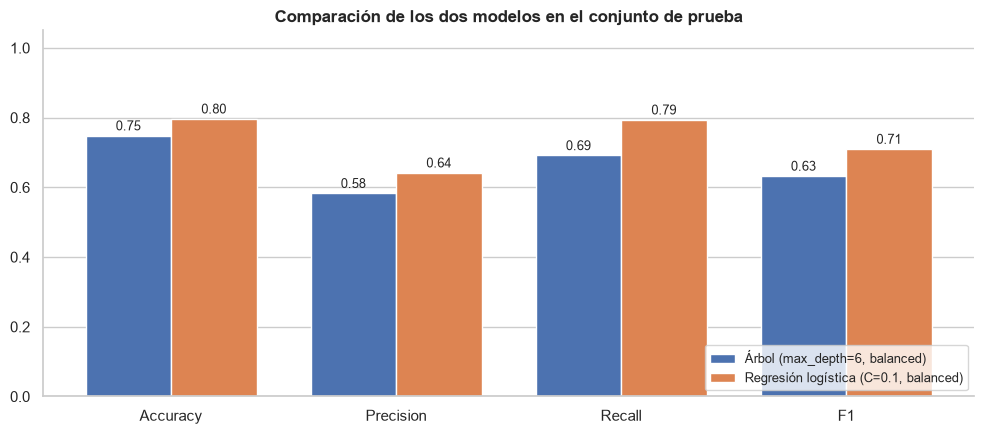

In [67]:
fig, ax = plt.subplots(figsize=(10, 4.5))
mets = ["Accuracy", "Precision", "Recall", "F1"]
pos = np.arange(len(mets))
for i, (nombre, color) in enumerate(zip(comparacion.index[1:], [COL_NO, COL_SI])):
    valores = comparacion.loc[nombre, mets].values.astype(float)
    barras = ax.bar(pos + (i - 0.5) * 0.38, valores, width=0.38, color=color, label=nombre)
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=9)
ax.set_xticks(pos)
ax.set_xticklabels(mets)
ax.set_ylim(0, 1.05)
ax.set_title("Comparación de los dos modelos en el conjunto de prueba")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## 5.4 ¿Cuál es el mejor modelo para TransAndes?

Nosotros elegimos la regresión logística balanceada. La elección no es por el accuracy (aunque también lo gana), sino por lo que definimos en la Fase 1:

1. Prioridad = recall (no dejar escapar retrasos). La logística detecta el 79 % de los pedidos que llegan tarde, frente al 69 % del árbol. En el grupo de prueba eso son 77 pedidos tardíos más que la empresa podría haber anticipado (597 vs. 520), y 77 falsos negativos menos, que era el error más caro.
2. Normalmente subir el recall cuesta precision, pero aquí la logística también tiene mejor precision (0,64 vs. 0,58) y menos falsas alarmas (333 vs. 372). Su F1 (0,71) es el más alto. Es decir, no hay un trade-off: es mejor en todo.
3. No sobreajusta (train = test), mientras que el árbol muestra una brecha leve.
4. Entrega una probabilidad de retraso para cada pedido. Esto es muy útil para operar porque  permite ordenar los despachos del día por riesgo y atender primero los más críticos si los recursos no alcanzan para todos, y permite mover el umbral según el presupuesto.
5. Sus coeficientes son interpretables y cuentan la misma historia que el EDA.

¿Y por qué no gana el árbol, si capta mejor las combinaciones? Porque la relación más fuerte (a más distancia, más riesgo) es bastante suave y continua, y la logística la representa con un solo coeficiente, mientras que el árbol la tiene que aproximar con escalones. Además, le ayudamos a la logística con la variable `hora_pico`. El árbol sigue siendo valioso para comunicar, sus primeras reglas ("si la ruta pasa de 54 km…", "si llueve fuerte y el conductor tiene menos de 9 años…") son fáciles de explicar en una reunión de operaciones.

El mensaje para la gerencia es que  con la información que ya tiene al despachar, el modelo encuentra 8 de cada 10 pedidos que van a llegar tarde, y cuando lanza una alerta acierta en casi 2 de cada 3 casos.


## 5.5 La perilla del umbral: más alertas o alertas más seguras

Por defecto, la logística dice "tardía" si la probabilidad es mayor a 0,5. Pero ese umbral lo puede decidir la gerencia según su presupuesto para intervenir pedidos, bajar el umbral detecta más retrasos a cambio de más falsas alarmas y  subirlo hace lo contrario.

In [68]:
prob_test = logistica.predict_proba(X_test_esc)[:, 1]   # probabilidad de llegar tarde de cada pedido

filas = []
for umbral in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_u = (prob_test >= umbral).astype(int)
    fila = {"Umbral": umbral}
    fila.update(fila_comparativa("", y_test, pred_u))
    fila.pop("Modelo")
    fila["% de pedidos alertados"] = pred_u.mean()
    filas.append(fila)

tabla_umbral = pd.DataFrame(filas).set_index("Umbral")
tabla_umbral.round(3)

,Accuracy,Precision,Recall,F1,Tardías detectadas,Tardías que se escapan (FN),Falsas alarmas (FP),Pedidos alertados,% de pedidos alertados
Umbral,,,,,,,,,
0.30,0.70,0.51,0.91,0.66,684,68,648,1332,0.56
0.40,0.75,0.57,0.85,0.68,636,116,476,1112,0.46
0.50,0.80,0.64,0.79,0.71,597,155,333,930,0.39
0.60,0.82,0.71,0.70,0.70,527,225,217,744,0.31
0.70,0.82,0.78,0.61,0.68,461,291,134,595,0.25



- Con umbral 0,5  se alerta el 39 % de los pedidos, se detecta el 79 % de los retrasos y 64 % de las alertas son correctas.
- Si TransAndes tiene capacidad para intervenir más pedidos, bajar a 0,4 detecta el 85 % de los retrasos (39 más), alertando al 46 % de los pedidos. Bajar a 0,3 detecta el 91 %, pero ya se alerta más de la mitad de los despachos y casi la mitad de las alertas son falsas.
- Si los recursos son muy limitados, subir a 0,6 reduce las falsas alarmas a 217 y la precision sube a 71 %, a cambio de detectar solo el 70 %.

Nuestra sugerencia es mantener 0,5 como punto de partida, porque tiene el mejor F1, y considerar 0,4 si las acciones preventivas son baratas como por ejemplo, avisar al cliente o cambiar la hora de salida. La decisión final depende del costo real de cada acción y de cada penalidad, que no está en los datos.


## 5.6 Así se usaría en el momento del despacho

Inventamos tres pedidos y le pedimos al modelo su probabilidad de llegar tarde. Usamos la misma función `preparar_X()` y el mismo escalador, para que los pedidos nuevos pasen exactamente por la misma transformación que los de entrenamiento. 

In [69]:
nuevos = pd.DataFrame({
    "distancia_km":                [8, 30, 120],
    "peso_kg":                     [6, 180, 1300],
    "num_paradas":                 [3, 7, 12],
    "hora_salida":                 [11, 10, 18],
    "experiencia_conductor_anios": [10, 4, 0.5],
    "edad_vehiculo_anios":         [2, 7, 14],
    "valor_pedido_COP":            [150_000, 300_000, 900_000],
    "zona_destino":                ["Urbana", "Periurbana", "Rural"],
    "clima":                       ["Soleado", "Nublado", "Lluvia fuerte"],
    "tipo_vehiculo":               ["Moto", "Furgón", "Camión"],
    "prioridad":                   ["Normal", "Normal", "Express"],
    "centro_distribucion":         ["Cali", "Bogotá", "Medellín"],
    "dia_semana":                  ["Martes", "Miércoles", "Sábado"],
    "tipo_cliente":                ["Hogar", "Empresa", "Tienda"],
}, index=["Pedido A", "Pedido B", "Pedido C"])
nuevos["hora_pico"] = (nuevos["hora_salida"].between(7, 9) | nuevos["hora_salida"].between(17, 19)).astype(int)

X_nuevos = preparar_X(nuevos).reindex(columns=X.columns, fill_value=0)   # mismas columnas que en el entrenamiento
prob = logistica.predict_proba(escalador.transform(X_nuevos))[:, 1]

resultado = nuevos[["zona_destino", "distancia_km", "num_paradas", "hora_salida", "clima", "experiencia_conductor_anios"]].copy()
resultado["Prob. de llegar tarde"] = (prob * 100).round(1).astype(str) + " %"
resultado["Alerta"] = np.where(prob >= 0.5, "⚠️ En riesgo", "✅ Normal")
resultado

,zona_destino,distancia_km,num_paradas,hora_salida,clima,experiencia_conductor_anios,Prob. de llegar tarde,Alerta
Pedido A,Urbana,8,3,11,Soleado,10.00,0.4 %,✅ Normal
Pedido B,Periurbana,30,7,10,Nublado,4.00,26.4 %,✅ Normal
Pedido C,Rural,120,12,18,Lluvia fuerte,0.50,100.0 %,⚠️ En riesgo



- **Pedido A** (urbano, 8 km, 3 paradas, sol, a media mañana, conductor con 10 años de experiencia, moto nueva): riesgo prácticamente nulo.
- **Pedido B** (periurbano, 30 km, 7 paradas, nublado, furgón, conductor con 4 años): un caso intermedio, cercano al promedio de la empresa.
- **Pedido C** (rural, 120 km, 12 paradas, lluvia fuerte, sale a las 18 h, conductor nuevo, camión viejo, Express): reúne casi todos los factores de riesgo, y el modelo está casi seguro de que llegará tarde. Con este pedido la empresa debería actuar **antes** de que salga: otro conductor, otra hora, menos paradas o, como mínimo, avisarle al cliente y ajustar la promesa de entrega.


---
# Fase 6 · Recomendaciones

## 6.1 ¿Qué variables están más relacionadas con los retrasos?

Juntamos tres fuentes de evidencia: 
1. El EDA (tamaño del efecto de las pruebas estadísticas de la Fase 2)
2. La importancia en el árbol
3. El coeficiente de la logística (en valor absoluto). Para las categóricas sumamos las importancias / tomamos el mayor coeficiente de sus dummies, y así las comparamos como una sola variable.

In [70]:
def variable_original(columna):
    for cat in ORDEN_CATEGORIAS:
        if columna.startswith(cat + "_"):
            return cat
    return "hora_salida" if columna == "hora_pico" else columna   # hora_pico es parte del efecto de la hora

imp_arbol = pd.Series(arbol.feature_importances_, index=X.columns).groupby(variable_original).sum()
coef_abs = pd.Series(np.abs(logistica.coef_[0]), index=X.columns).groupby(variable_original).max()

ranking = pd.DataFrame({
    "Efecto en el EDA": tests["tamaño del efecto"].astype(float),
    "Importancia árbol": imp_arbol,
    "|Coef.| logística": coef_abs,
})
# Cada columna en una escala de 0 a 1 (dividiendo por su máximo) para poder promediarlas
ranking_norm = ranking / ranking.max()
ranking["Puntaje promedio (0-1)"] = ranking_norm.mean(axis=1)
ranking = ranking.sort_values("Puntaje promedio (0-1)", ascending=False)
ranking.round(3)

,Efecto en el EDA,Importancia árbol,|Coef.| logística,Puntaje promedio (0-1)
distancia_km,0.45,0.46,1.11,1.00
clima,0.25,0.12,0.77,0.50
num_paradas,0.26,0.10,0.61,0.45
experiencia_conductor_anios,0.22,0.07,0.66,0.41
zona_destino,0.40,0.01,0.33,0.40
edad_vehiculo_anios,0.19,0.07,0.56,0.36
hora_salida,0.03,0.07,0.57,0.24
prioridad,0.12,0.04,0.41,0.24
tipo_vehiculo,0.17,0.00,0.27,0.21
centro_distribucion,0.10,0.00,0.33,0.17


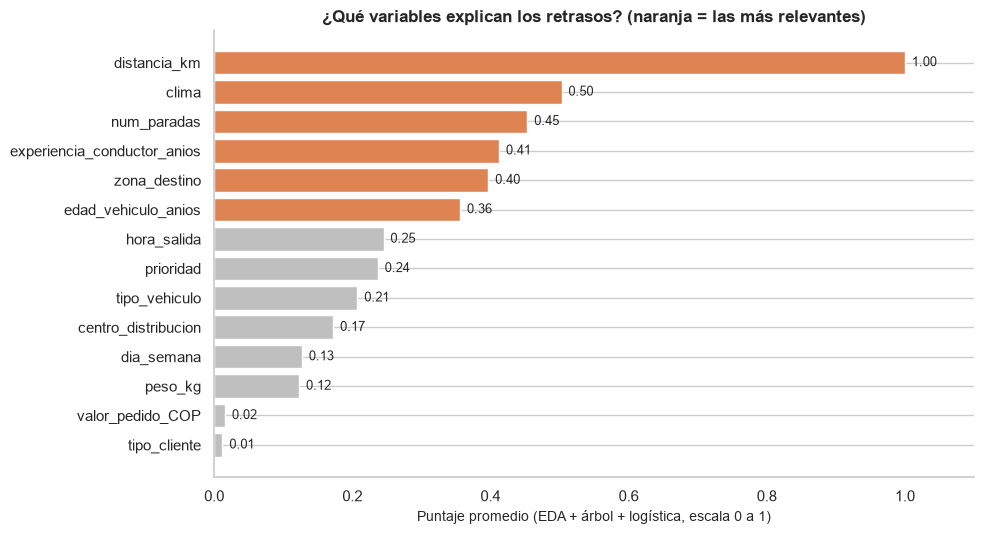

In [71]:
fig, ax = plt.subplots(figsize=(10, 5.5))
r = ranking["Puntaje promedio (0-1)"].iloc[::-1]
colores = [COL_SI if v >= 0.35 else "#BFBFBF" for v in r.values]
ax.barh(r.index, r.values, color=colores)
for i, v in enumerate(r.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlim(0, 1.1)
ax.set_xlabel("Puntaje promedio (EDA + árbol + logística, escala 0 a 1)")
ax.set_title("¿Qué variables explican los retrasos? (naranja = las más relevantes)")
plt.tight_layout()
plt.show()


Las tres fuentes coinciden bastante. Agrupamos las variables en tres niveles:

Factores principales:
1. Distancia (y, con ella, la zona rural): primera en las tres fuentes. La zona sale más abajo en el árbol solo porque la distancia ya contiene esa información.
2. Clima, sobre todo la lluvia fuerte.
3. Número de paradas.
4. Experiencia del conductor (efecto protector).
5. Edad del vehículo.

Factores secundarios: 
* hora de salida (pero solo como hora pico; como número no dice nada)
* prioridad Express.
* tipo de vehículo (el furgón es el peor) 
* centro de distribucióN.

Sin relación con el retraso: valor del pedido, tipo de cliente, peso (más allá de distinguir el vehículo) y día de la semana (con un efecto menor el viernes y el sábado).

La conclusión de negocio es clara, los retrasos dependen de decisiones operativas (qué ruta, cuántas paradas, a qué hora, con qué conductor y qué vehículo) y de condiciones externas (clima, distancia), no del tipo de cliente. 


Antes de escribir las recomendaciones, calculamos algunas cifras de apoyo sobre la base limpia:

In [72]:
d = df_limpio
apoyo = {
    "Tardías en zona rural": d.loc[d["zona_destino"] == "Rural", "tardia"].mean(),
    "Tardías en rutas de más de 60 km": d.loc[d["distancia_km"] > 60, "tardia"].mean(),
    "Tardías con 1 a 8 paradas": d.loc[d["num_paradas"] <= 8, "tardia"].mean(),
    "Tardías con más de 8 paradas": d.loc[d["num_paradas"] > 8, "tardia"].mean(),
    "Tardías saliendo en hora pico": d.loc[d["hora_pico"] == 1, "tardia"].mean(),
    "Tardías saliendo fuera de hora pico": d.loc[d["hora_pico"] == 0, "tardia"].mean(),
    "Tardías con conductor de < 3 años": d.loc[d["experiencia_conductor_anios"] < 3, "tardia"].mean(),
    "Tardías con conductor de 8 años o más": d.loc[d["experiencia_conductor_anios"] >= 8, "tardia"].mean(),
    "Tardías con vehículo de 0 a 5 años": d.loc[d["edad_vehiculo_anios"] <= 5, "tardia"].mean(),
    "Tardías con vehículo de 10 años o más": d.loc[d["edad_vehiculo_anios"] >= 10, "tardia"].mean(),
    "Tardías con lluvia fuerte": d.loc[d["clima"] == "Lluvia fuerte", "tardia"].mean(),
    "Tardías en pedidos Express": d.loc[d["prioridad"] == "Express", "tardia"].mean(),
    "Tardías en el centro Bogotá": d.loc[d["centro_distribucion"] == "Bogotá", "tardia"].mean(),
    "Tardías en los otros 3 centros": d.loc[d["centro_distribucion"] != "Bogotá", "tardia"].mean(),
}
pd.Series(apoyo).mul(100).round(1).rename("% de pedidos tardíos").to_frame()

,% de pedidos tardíos
Tardías en zona rural,69.40
Tardías en rutas de más de 60 km,69.90
Tardías con 1 a 8 paradas,26.30
Tardías con más de 8 paradas,43.80
Tardías saliendo en hora pico,41.50
Tardías saliendo fuera de hora pico,25.90
Tardías con conductor de < 3 años,40.40
Tardías con conductor de 8 años o más,17.30
Tardías con vehículo de 0 a 5 años,23.80
Tardías con vehículo de 10 años o más,39.30


In [73]:
# ¿Qué pasa en Bogotá? Lo comparamos dentro de cada zona para descartar que sea solo porque despacha más rural
tabla_bog = d.pivot_table(index="centro_distribucion", columns="zona_destino", values="tardia", aggfunc="mean") * 100
tabla_bog.loc[["Cali", "Bogotá", "Medellín", "Barranquilla"], ["Urbana", "Periurbana", "Rural"]].round(1)

zona_destino,Urbana,Periurbana,Rural
centro_distribucion,,,
Cali,16.70,26.10,65.70
Bogotá,25.10,37.80,78.40
Medellín,15.50,29.90,66.10
Barranquilla,16.70,30.20,64.00


## 6.2 Recomendaciones para la gerencia de operaciones


1. Calcular la probabilidad de retraso de cada pedido antes de que salga y marcar en rojo los que superan el umbral (0,5, o 0,4 si hay capacidad). Con los datos de prueba, esto permite anticipar 8 de cada 10 retrasos. A los pedidos en rojo se les aplica alguna de las acciones de abajo y, como mínimo, se le avisa al cliente (en especial a los clientes empresariales, que son los que generan penalidades). Ordenar los despachos por probabilidad ayuda a priorizar cuando los recursos no alcanzan.


2. Con 1 a 8 paradas llega tarde el 26 % de los pedidos, con más de 8, el 44 %. Los furgones hacen en promedio 9 paradas por ruta (las motos 4) y son el vehículo con más retrasos en todas las zonas. Proponemos fijar un tope de 8 paradas por ruta y dividir las rutas más cargadas entre dos vehículos.


3. Con conductores de menos de 3 años llega tarde el 40 % de los pedidos, con 8 años o más, el 17 %. El árbol mostró que, con lluvia fuerte en rutas cortas, un conductor de más de 9 años baja el retraso de 59 % a 15 %. Las rutas rurales, largas, con lluvia o Express deberían ir a los conductores veteranos, y los nuevos deberían empezar por rutas urbanas cortas o acompañados.

4. Saliendo entre 7-9 h o 17-19 h llega tarde el 41,5 % de los pedidos, en el resto del día, el 26 %. Adelantar las salidas a las 5-6 h o moverlas a media mañana (10-16 h), sobre todo en rutas de más de 54 km, donde el árbol mostró que la hora pico sube el retraso de 39 % a 68 %.


5. En zona rural llega tarde el 69 % de los pedidos y en rutas de más de 60 km, el 70 %, con esas cifras, el problema no es solo de ejecución, la ventana prometida es poco realista. Proponemos ventanas más amplias para destinos rurales (o venderlas como entrega "estándar rural"). Además, cuando el pronóstico sea de lluvia fuerte (60 % de retraso), activar un protocolo que sea salir más temprano, reducir paradas y avisar al cliente.


6. Con vehículos de 0 a 5 años llega tarde el 24 %, con vehículos de 10 años o más, el 39 %. Priorizar mantenimiento preventivo de los vehículos más viejos y no asignarlos a rutas largas o rurales.


7. Bogotá tiene 38 % de retrasos frente a 28 % de los otros tres centros, y es peor en las tres zonas (urbana 25 % vs 16 %, periurbana 38 % vs 29 %, rural 78 % vs 65 %). No se explica por el tipo de destino, así que vale la pena investigar causas locales (tráfico, procesos de alistamiento, ubicación del centro), ya que no están en los datos.

Además los pedidos Express se retrasan 41 % (vs 28 % los normales). Antes de aceptar un Express a una zona rural o en hora pico, convendría verificar que la ventana corta sea realmente cumplible.


## 6.3 Limitaciones del análisis


* Correlación no es causalidad, por que no podemos afirmar que cambiar un furgón por una moto reduzca el retraso ya que  el furgón también hace más paradas y lleva más peso. Las recomendaciones deberían probarse primero con un piloto como por ejemplo, en un solo centro y medir el resultado.

* El clima puede no conocerse con certeza al despachar. La variable dice "clima en la ruta", que probablemente se registró después. 

* Los nulos se imputaron. Alrededor del 45 % de los pedidos tenía al menos un dato faltante y lo reemplazamos con medianas o con la categoría "Sin dato". Esto suaviza las diferencias entre pedidos. Además, las medianas se calcularon con toda la base antes de dividir en train y test, lo más estricto sería calcularlas solo con train, aunque con medianas el efecto es mínimo.

*  Asumimos que las distancias negativas eran errores de signo ya la evidencia lo apoyaba, pero no es algo  seguro y convertimos a nulo las horas > 23, pesos y paradas en 0 y pesos absurdos para su vehículo. Otros criterios darían resultados un poco distintos.

* No hay información de tráfico real, estado de las vías, tiempo de alistamiento en bodega, ventana prometida exacta (cuántas horas), ni de por qué se retrasó cada pedido. Con ellas el modelo podría mejorar.

* Entrenamos con pedidos de 2025 y una sola partición 70/30. Si la operación cambia (nuevas rutas, nuevos centros), el modelo habría que reentrenarlo periódicamente. Las métricas de validación cruzada serian parecidas a las de prueba.
*  .Dijimos que un falso negativo es más caro que un falso positivo, pero sin el costo de una penalidad o de una acción preventiva no podemos calcular el umbral óptimo entonces  lo dejamos como una decisión de la gerencia.




## 6.4 Conclusión


* Sí, es posible predecir con buena anticipación qué pedidos llegarán tarde. Con la información disponible al despacho, la regresión logística detecta el 79 % de los pedidos que terminan llegando tarde frente a 0 % si no se usa ningún modelo, con una precision de 64 % y sin sobreajuste.

* Las condiciones que aumentan el riesgo son las rutas largas y rurales, lluvia (sobre todo fuerte), muchas paradas, salir en hora pico, conductores con poca experiencia, vehículos viejos, pedidos Express y despachar desde Bogotá. El tipo de cliente y el valor del pedido no tienen relación con el retraso.

* Varias de esas condiciones dependen de decisiones de la propia empresa  como cuántas paradas, a qué hora sale, qué conductor y qué vehículo se asigna, qué ventana se promete. Por eso, además de alertar, el modelo le dice a TransAndes dónde actuar para reducir el 31 % de pedidos tardíos.


## 7 Declaración de uso de IA 

Herramientas utilizadas:Claude
•	Ejecutamos el notebook completo de principio a fin para  saber que todo funcionaba  bien  y verificamos que las cifras del texto coincidieran con las salidas del código.
 Como apoyo para escribir las primeras versiones de código y revisar  ya que algunos si son un poco largos  , no como fuente de datos ya que  todas las cifras salen del archivo logistica_entregas.csv entregado para que desarrollaramos el proyecto. Tambien nos apoyamos en la IA para revisar el orden y estructura del cuaderno para que todo este bien enumerado y que nos podamos guiar. 
